# Gaining semantic encodings using Text-to-Text transfer transformer (T5-small google)

In this notebook, we study token-level generative semantic communication using the T5-small encoder–decoder model under a noisy wireless channel. Clean encoder hidden states (token-level representations) are extracted from the T5 encoder and transmitted through a simulated communication pipeline consisting of uniform 8-bit quantization, BPSK modulation, a Rayleigh fading channel with additive white Gaussian noise (AWGN), and MMSE equalization, followed by dequantization. The reconstructed encoder representations are then fed to the T5 decoder via the encoder-output interface (encoder_outputs = BaseModelOutput(last_hidden_state=...)), which preserves the standard encoder–decoder conditioning path expected by the model and yields stable decoding at high SNR. Decoding via direct embedding injection (inputs_embeds) was also tested and found to cause catastrophic collapse even in the absence of channel noise; this behavior is documented as an analysis result but is not used for robustness evaluation. Performance is evaluated at SNR values of 20 dB, 15 dB, and 10 dB on a fixed diagnostic subset of 15 sentences. Two classes of metrics are reported: (i) embedding-level metrics, specifically token-level cosine similarity between clean and reconstructed encoder representations, which degrade smoothly with decreasing SNR, and (ii) behavior-level metrics, based on automatic decoding stability buckets (STABLE, DEGRADED, COLLAPSED) and the derived collapse probability. Results show a clear metric–behavior mismatch, where cosine similarity degrades gradually while decoding behavior exhibits a sharp, phase-transition-like collapse as SNR decreases. All bucket definitions, thresholds, decoding paths, and evaluation procedures are frozen in this notebook and serve as the canonical T5-small baseline for subsequent comparative experiments.

## dependencies

In [ ]:
# ===== Core Python =====
import json
import numpy as np

# ===== Torch =====
import torch

# ===== Transformers =====
from transformers import T5EncoderModel, T5ForConditionalGeneration, T5Tokenizer

# ===== (Optional, for later analysis/logging) =====
import pandas as pd


In [ ]:
## Optional: mount Google Drive (only when running on Colab).
## Paths below default to the corpora shipped in this repository, so this
## cell can be skipped when running locally.
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running on Colab - using repository-relative paths.')


Mounted at /content/drive


In [ ]:
import os

# Repository root, resolved so the notebook runs from Colab or a local clone.
REPO_ROOT = os.environ.get('GENSEMCOM_ROOT', os.path.abspath(os.path.join(os.getcwd(), '..')))
DATA_DIR = os.environ.get('GENSEMCOM_DATA', os.path.join(REPO_ROOT, 'data'))
CORPUS_10K = os.path.join(DATA_DIR, 'processed', '10k_sentences.json')
CORPUS_1K = os.path.join(DATA_DIR, 'raw', '1k_sentences_random.json')
SAVE_DIR = os.environ.get('GENSEMCOM_OUT', os.path.join(REPO_ROOT, 'results'))
os.makedirs(SAVE_DIR, exist_ok=True)


## checking if encoding works

In [ ]:
import json

DATASET_PATH = CORPUS_10K

with open(DATASET_PATH, "r", encoding="utf-8") as f:
    data = json.load(f)

sentences = data["sentences"]

print("Total sentences:", len(sentences))
print("Sample sentence:", sentences[0])


Total sentences: 10000
Sample sentence: Various anarchist schools of thought formed during this period.


In [ ]:
import torch
from transformers import T5Tokenizer, T5ForConditionalGeneration

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

tokenizer = T5Tokenizer.from_pretrained("t5-small")
model = T5ForConditionalGeneration.from_pretrained("t5-small").to(device)
model.eval()


Using device: cuda


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565


config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/242M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

T5ForConditionalGeneration(
  (shared): Embedding(32128, 512)
  (encoder): T5Stack(
    (embed_tokens): Embedding(32128, 512)
    (block): ModuleList(
      (0): T5Block(
        (layer): ModuleList(
          (0): T5LayerSelfAttention(
            (SelfAttention): T5Attention(
              (q): Linear(in_features=512, out_features=512, bias=False)
              (k): Linear(in_features=512, out_features=512, bias=False)
              (v): Linear(in_features=512, out_features=512, bias=False)
              (o): Linear(in_features=512, out_features=512, bias=False)
              (relative_attention_bias): Embedding(32, 8)
            )
            (layer_norm): T5LayerNorm()
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (1): T5LayerFF(
            (DenseReluDense): T5DenseActDense(
              (wi): Linear(in_features=512, out_features=2048, bias=False)
              (wo): Linear(in_features=2048, out_features=512, bias=False)
              (dropout): Drop

In [ ]:
sentence = "Various anarchist schools of thought formed during this period."

inputs = tokenizer(
    sentence,
    return_tensors="pt",
    padding=True,
    truncation=True
).to(device)

with torch.no_grad():
    output_ids = model.generate(
        **inputs,
        max_length=50
    )

decoded_text = tokenizer.decode(output_ids[0], skip_special_tokens=True)

print("Input sentence:")
print(sentence)
print("\nDecoded output:")
print(decoded_text)


Input sentence:
Various anarchist schools of thought formed during this period.

Decoded output:
Während dieser Zeit entstanden verschiedene anarchistische Gedankenschulen.


Encoding/decoding roundtrip validated.

### extracting encoder hidden states


In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

tokenizer = T5Tokenizer.from_pretrained("t5-small")
encoder = T5EncoderModel.from_pretrained("t5-small").to(device)
encoder.eval()

sentence = "Various anarchist schools of thought formed during this period."

inputs = tokenizer(
    sentence,
    return_tensors="pt",
    padding=True,
    truncation=True
).to(device)

with torch.no_grad():
    encoder_outputs = encoder(**inputs)

hidden_states = encoder_outputs.last_hidden_state
attention_mask = inputs.attention_mask

print("Hidden states shape:", hidden_states.shape)
print("Attention mask shape:", attention_mask.shape)
print("Attention mask:", attention_mask)


Hidden states shape: torch.Size([1, 14, 512])
Attention mask shape: torch.Size([1, 14])
Attention mask: tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]], device='cuda:0')


In [ ]:
# Remove batch dimension
token_embeddings = hidden_states[0]  # shape: [14, 512]

print("Token-level embeddings shape:", token_embeddings.shape)


Token-level embeddings shape: torch.Size([14, 512])


### 16-bit encoding first for sanity check

so we can see if the decoder works nicely or not using quantization.

In [ ]:
# Encode sentence
with torch.no_grad():
    encoder_outputs = encoder(**inputs)

hidden_states = encoder_outputs.last_hidden_state[0]      # [T, 512]
attention_mask = inputs.attention_mask[0]                # [T]

# Keep only real tokens
token_embeddings = hidden_states[attention_mask == 1]    # [T_real, 512]

print("Token embeddings shape:", token_embeddings.shape)


Token embeddings shape: torch.Size([14, 512])


In [ ]:
# Convert to CPU numpy for quantization
emb_np = token_embeddings.cpu().numpy()

emin = emb_np.min()
emax = emb_np.max()

# 16-bit quantization
q_levels = 2**16 - 1  # 65535

emb_q = np.round((emb_np - emin) / (emax - emin) * q_levels).astype(np.uint16)

print("Quantized dtype:", emb_q.dtype)
print("Quantized min/max:", emb_q.min(), emb_q.max())


Quantized dtype: uint16
Quantized min/max: 0 65535


In [ ]:
# Dequantize
emb_rec = (emb_q.astype(np.float32) / q_levels) * (emax - emin) + emin

emb_rec = torch.tensor(emb_rec, device=device)

print("Reconstructed embedding shape:", emb_rec.shape)


Reconstructed embedding shape: torch.Size([14, 512])


In [ ]:
# Reconstruct full sequence with padding
T_full = hidden_states.shape[0]
D = hidden_states.shape[1]

reconstructed_hidden = torch.zeros((T_full, D), device=device)
reconstructed_hidden[attention_mask == 1] = emb_rec

# Add batch dimension
reconstructed_hidden = reconstructed_hidden.unsqueeze(0)  # [1, T, 512]
attention_mask_batch = inputs.attention_mask


In [ ]:
from transformers import T5ForConditionalGeneration

model = T5ForConditionalGeneration.from_pretrained("t5-small").to(device)
model.eval()

print("Decoder model loaded.")


Decoder model loaded.


In [ ]:
from transformers.modeling_outputs import BaseModelOutput


In [ ]:
# Wrap reconstructed hidden states in proper ModelOutput
encoder_outputs_wrapped = BaseModelOutput(
    last_hidden_state=reconstructed_hidden
)

with torch.no_grad():
    decoded_ids = model.generate(
        encoder_outputs=encoder_outputs_wrapped,
        attention_mask=attention_mask_batch,
        max_length=50
    )

decoded_text = tokenizer.decode(decoded_ids[0], skip_special_tokens=True)

print("Decoded text after 16-bit quantization:")
print(decoded_text)


Decoded text after 16-bit quantization:
Während dieser Zeit entstanden verschiedene anarchistische Gedankenschulen.


Pipeline runs end to end without errors.

## 8-bit quantization without noise

In [ ]:
# fixing sentences (initial 15) for the test
import random

# Fix seed for reproducibility
random.seed(42)

NUM_SAMPLES = 15

selected_indices = random.sample(range(len(sentences)), NUM_SAMPLES)
batch_sentences = [sentences[i] for i in selected_indices]

print("Selected indices:", selected_indices)
print("\nSample sentences:\n")

for i, s in enumerate(batch_sentences):
    print(f"{i+1}. {s}")


Selected indices: [1824, 409, 4506, 4012, 3657, 2286, 1679, 8935, 1424, 9674, 6912, 520, 488, 1535, 3582]

Sample sentences:

1. Most eggs contain the pigment melanin which raises their temperature through the absorption of light and also protects them against ultraviolet radiation.
2. Lincoln believed the federal government had limited responsibility to the millions of freedmen.
3. Public opinion shifted in America following television personality Sherri Finkbine's discovery during her fifth month of pregnancy that she had been exposed to thalidomide.
4. Carpets have been produced in the region for thousands of years and traditionally done by women.
5. History

The Angolan economy has been dominated by the production of raw materials and the use of cheap labor since European rule began in the sixteenth century.
6. Some courts have samples of a notice of appeal on the court's own web site.
7. Many of the animals who participated in the rebellion are dead or old.
8. Numerous formerly pr

In [ ]:
import re

def normalize_text(s: str) -> str:
    # Replace newlines/tabs with space
    s = re.sub(r'[\n\t]+', ' ', s)
    # Collapse multiple spaces
    s = re.sub(r'\s+', ' ', s)
    # Trim
    return s.strip()

clean_batch_sentences = [normalize_text(s) for s in batch_sentences]

print("Before → After (showing differences only):\n")
for i, (before, after) in enumerate(zip(batch_sentences, clean_batch_sentences)):
    if before != after:
        print(f"{i+1}. BEFORE: {before}")
        print(f"   AFTER : {after}\n")

print("Final cleaned batch:\n")
for i, s in enumerate(clean_batch_sentences):
    print(f"{i+1}. {s}")


Before → After (showing differences only):

5. BEFORE: History

The Angolan economy has been dominated by the production of raw materials and the use of cheap labor since European rule began in the sixteenth century.
   AFTER : History The Angolan economy has been dominated by the production of raw materials and the use of cheap labor since European rule began in the sixteenth century.

Final cleaned batch:

1. Most eggs contain the pigment melanin which raises their temperature through the absorption of light and also protects them against ultraviolet radiation.
2. Lincoln believed the federal government had limited responsibility to the millions of freedmen.
3. Public opinion shifted in America following television personality Sherri Finkbine's discovery during her fifth month of pregnancy that she had been exposed to thalidomide.
4. Carpets have been produced in the region for thousands of years and traditionally done by women.
5. History The Angolan economy has been dominated by th

In [ ]:
# encoding the batch
# Encode 15 sentences with T5 encoder (token-level)

encoder.eval()

batch_token_embeddings = []
batch_attention_masks = []
batch_token_lengths = []

for idx, sentence in enumerate(clean_batch_sentences):
    inputs = tokenizer(
        sentence,
        return_tensors="pt",
        padding=True,
        truncation=True
    ).to(device)

    with torch.no_grad():
        outputs = encoder(**inputs)

    hidden_states = outputs.last_hidden_state[0]      # [T, 512]
    attention_mask = inputs.attention_mask[0]         # [T]

    # Remove padding (Option 2)
    token_embeddings = hidden_states[attention_mask == 1]  # [T_real, 512]

    batch_token_embeddings.append(token_embeddings)
    batch_attention_masks.append(attention_mask)
    batch_token_lengths.append(token_embeddings.shape[0])

    print(f"{idx+1:02d}. Tokens: {token_embeddings.shape[0]} | Text: {sentence[:60]}...")


01. Tokens: 29 | Text: Most eggs contain the pigment melanin which raises their tem...
02. Tokens: 17 | Text: Lincoln believed the federal government had limited responsi...
03. Tokens: 36 | Text: Public opinion shifted in America following television perso...
04. Tokens: 19 | Text: Carpets have been produced in the region for thousands of ye...
05. Tokens: 33 | Text: History The Angolan economy has been dominated by the produc...
06. Tokens: 20 | Text: Some courts have samples of a notice of appeal on the court'...
07. Tokens: 15 | Text: Many of the animals who participated in the rebellion are de...
08. Tokens: 20 | Text: Numerous formerly privileged business are now required to pa...
09. Tokens: 19 | Text: Other notable forms are the Apollo Citharoedus and the Apoll...
10. Tokens: 9 | Text: beyond the imagination or concept of men....
11. Tokens: 14 | Text: This situation is common for elements with an odd atomic num...
12. Tokens: 20 | Text: Gershwin strongly encouraged Ravel to co

In [ ]:
# santiy checks
print("\nSummary:")
print("Number of sentences:", len(batch_token_embeddings))
print("Min tokens:", min(batch_token_lengths))
print("Max tokens:", max(batch_token_lengths))
print("Average tokens:", sum(batch_token_lengths) / len(batch_token_lengths))



Summary:
Number of sentences: 15
Min tokens: 9
Max tokens: 36
Average tokens: 20.6


In [ ]:
# checking
# Concatenate all token embeddings into one big matrix
all_tokens = torch.cat(batch_token_embeddings, dim=0)  # [N_total_tokens, 512]

print("All tokens shape:", all_tokens.shape)


All tokens shape: torch.Size([309, 512])


In [ ]:
# quantizationnnn
# Move to CPU numpy for quantization
all_tokens_np = all_tokens.cpu().numpy()

emin = all_tokens_np.min()
emax = all_tokens_np.max()

q_levels = 255  # 8-bit

# Quantize
all_tokens_q = np.round(
    (all_tokens_np - emin) / (emax - emin) * q_levels
).astype(np.uint8)

print("Quantized dtype:", all_tokens_q.dtype)
print("Quantized range:", all_tokens_q.min(), all_tokens_q.max())


Quantized dtype: uint8
Quantized range: 0 255


In [ ]:
# de-quantize
# Dequantize back to float
all_tokens_rec = (
    all_tokens_q.astype(np.float32) / q_levels
) * (emax - emin) + emin

all_tokens_rec = torch.tensor(all_tokens_rec)

print("Reconstructed tokens shape:", all_tokens_rec.shape)


Reconstructed tokens shape: torch.Size([309, 512])


In [ ]:
#splitting into per sentence embeddings
reconstructed_batch_embeddings = []

cursor = 0
for length in batch_token_lengths:
    rec_tokens = all_tokens_rec[cursor:cursor + length]
    reconstructed_batch_embeddings.append(rec_tokens.to(device))
    cursor += length

print("Reconstructed sentences:", len(reconstructed_batch_embeddings))


Reconstructed sentences: 15


In [ ]:
# repadding the sentences
from transformers.modeling_outputs import BaseModelOutput

decoded_outputs = []

for idx, (orig_sentence, rec_tokens, attention_mask) in enumerate(
    zip(clean_batch_sentences, reconstructed_batch_embeddings, batch_attention_masks)
):
    # Original full length (with padding)
    T_full = attention_mask.shape[0]
    D = rec_tokens.shape[1]

    # Create padded tensor
    reconstructed_hidden = torch.zeros((T_full, D), device=device)
    reconstructed_hidden[attention_mask == 1] = rec_tokens

    # Add batch dimension
    reconstructed_hidden = reconstructed_hidden.unsqueeze(0)  # [1, T, 512]
    attention_mask_batch = attention_mask.unsqueeze(0)

    # Wrap as encoder output
    encoder_outputs_wrapped = BaseModelOutput(
        last_hidden_state=reconstructed_hidden
    )

    # Decode
    with torch.no_grad():
        decoded_ids = model.generate(
            encoder_outputs=encoder_outputs_wrapped,
            attention_mask=attention_mask_batch,
            max_length=60
        )

    decoded_text = tokenizer.decode(decoded_ids[0], skip_special_tokens=True)
    decoded_outputs.append(decoded_text)

    print(f"\n--- Sentence {idx+1} ---")
    print("Original :", orig_sentence)
    print("Decoded  :", decoded_text)



--- Sentence 1 ---
Original : Most eggs contain the pigment melanin which raises their temperature through the absorption of light and also protects them against ultraviolet radiation.
Decoded  : contain the pigment melanin which raises their temperature through the absorption of light and also protects them against ultraviolet radiation.

--- Sentence 2 ---
Original : Lincoln believed the federal government had limited responsibility to the millions of freedmen.
Decoded  : Lincoln Lincoln a eu l idée que Lincoln a et Lincoln believed the federal government had limited responsibility to millions of freedmen.

--- Sentence 3 ---
Original : Public opinion shifted in America following television personality Sherri Finkbine's discovery during her fifth month of pregnancy that she had been exposed to thalidomide.
Decoded  : ide, a thalidomide, was found in her fifth month of pregnancy.

--- Sentence 4 ---
Original : Carpets have been produced in the region for thousands of years and tradit

###  8-bit Quantization (No Channel)

At this point, we have validated the end-to-end semantic pipeline under **8-bit fixed-point quantization only**, without any wireless channel effects.

Key takeaways:
- Token-level T5 encoder representations are moderately robust to 8-bit quantization.
- Semantic meaning is largely preserved, but decoding quality degrades through:
  - multilingual drift,
  - repetition artifacts,
  - failure on short or abstract inputs.
- These effects occur **before** introducing channel noise, indicating that quantization itself is a non-trivial source of semantic distortion.

This stage establishes a clean baseline for subsequent experiments involving channel transmission and denoising.


- why? We first isolated the effect of quantization alone. Even without channel noise, 8-bit fixed-point quantization introduced semantic drift such as multilingual leakage and repetition, motivating further robustness analysis under channel impairments.

quantization alone causes these distortions.

In [ ]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# --- Recompute per-sentence cosine similarity ---
per_sentence_cosine = []

for clean_emb, rec_emb in zip(batch_token_embeddings, reconstructed_batch_embeddings):
    # L2 normalize token embeddings
    clean_norm = F.normalize(clean_emb, dim=1)
    rec_norm = F.normalize(rec_emb, dim=1)

    # Cosine similarity per token
    cos_per_token = (clean_norm * rec_norm).sum(dim=1)

    # Average over tokens
    per_sentence_cosine.append(cos_per_token.mean().item())

per_sentence_cosine = np.array(per_sentence_cosine)

# --- Print high-precision values ---
print("Per-sentence cosine similarity (high precision):")
for i, v in enumerate(per_sentence_cosine):
    print(f"Sentence {i+1:02d}: {v:.6f}")

print("\nSummary:")
print(f"Mean: {per_sentence_cosine.mean():.6f}")
print(f"Min : {per_sentence_cosine.min():.6f}")
print(f"Max : {per_sentence_cosine.max():.6f}")

# --- Plot (zoomed y-axis) ---
plt.figure(figsize=(8, 4))
plt.plot(
    range(1, len(per_sentence_cosine) + 1),
    per_sentence_cosine,
    marker='o',
    linewidth=1
)

plt.ylim(0.995, 1.0)
plt.xlabel("Sentence index")
plt.ylabel("Cosine similarity")
plt.title("Per-sentence semantic similarity (8-bit quantization, no channel)")
plt.grid(True)
plt.show()


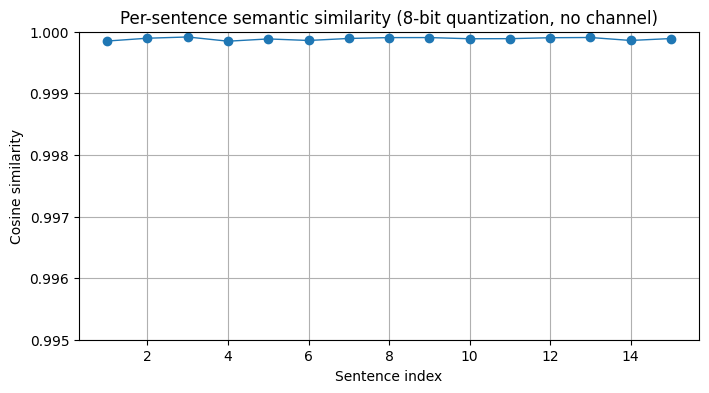

Per-sentence cosine similarity (high precision):
Sentence 01: 0.999849
Sentence 02: 0.999895
Sentence 03: 0.999915
Sentence 04: 0.999846
Sentence 05: 0.999883
Sentence 06: 0.999858
Sentence 07: 0.999891
Sentence 08: 0.999904
Sentence 09: 0.999905
Sentence 10: 0.999886
Sentence 11: 0.999887
Sentence 12: 0.999903
Sentence 13: 0.999906
Sentence 14: 0.999858
Sentence 15: 0.999889

Summary:
Mean: 0.999885
Min : 0.999846

`Although per-token cosine similarity remains high under 8-bit quantization, the decoder output exhibits noticeable semantic artifacts, indicating that cosine similarity alone is insufficient to characterize end-to-end semantic fidelity`

## Channel Transmission

`Stage A4`
- T5 encoder
→ token embeddings
→ 8-bit quantization
→ bitstream
→ BPSK
→ Rayleigh + AWGN
→ demodulation
→ dequantization
→ repadding
→ T5 decoder


### initial channel transmission using all constraints

In [ ]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

from transformers import (
    T5Tokenizer,
    T5EncoderModel,
    T5ForConditionalGeneration
)
from transformers.modeling_outputs import BaseModelOutput

device = "cuda" if torch.cuda.is_available() else "cpu"


In [ ]:
tokenizer = T5Tokenizer.from_pretrained("t5-small")
encoder = T5EncoderModel.from_pretrained("t5-small").to(device)
model = T5ForConditionalGeneration.from_pretrained("t5-small").to(device)

encoder.eval()
model.eval()


In [ ]:
sentence = "Most eggs contain the pigment melanin which raises their temperature through the absorption of light and also protects them against ultraviolet radiation."

print("Input sentence:")
print(sentence)


Input sentence:
Most eggs contain the pigment melanin which raises their temperature through the absorption of light and also protects them against ultraviolet radiation.


In [ ]:
# removing padding and encoding
inputs = tokenizer(
    sentence,
    return_tensors="pt",
    padding=True,
    truncation=True
).to(device)

with torch.no_grad():
    enc_out = encoder(**inputs)

hidden_states = enc_out.last_hidden_state[0]      # [T, 512]
attention_mask = inputs.attention_mask[0]         # [T]

token_embeddings = hidden_states[attention_mask == 1]  # [T_real, 512]

T_real, D = token_embeddings.shape
print(f"Tokens: {T_real}, Dim: {D}")


Tokens: 29, Dim: 512


In [ ]:
emb_np = token_embeddings.cpu().numpy()

emin = emb_np.min()
emax = emb_np.max()
q_levels = 255

emb_q = np.round(
    (emb_np - emin) / (emax - emin) * q_levels
).astype(np.uint8)


In [ ]:
# uint8 → bits
bitstream = np.unpackbits(emb_q.flatten())

print("Total bits:", bitstream.size)


Total bits: 118784


In [ ]:
# 0 → -1, 1 → +1
symbols = 2 * bitstream.astype(np.float32) - 1


In [ ]:
def rayleigh_awgn_channel(symbols, snr_db):
    snr_linear = 10 ** (snr_db / 10)

    # Rayleigh fading
    h = (np.random.randn(*symbols.shape) + 1j * np.random.randn(*symbols.shape)) / np.sqrt(2)

    # AWGN noise
    noise_var = 1 / snr_linear
    noise = np.sqrt(noise_var / 2) * (
        np.random.randn(*symbols.shape) + 1j * np.random.randn(*symbols.shape)
    )

    # Channel
    r = h * symbols + noise

    # Equalization (MMSE-lite)
    r_eq = np.real(np.conj(h) * r / (np.abs(h) ** 2 + noise_var))

    return r_eq


In [ ]:
SNRs = [20, 10, 5, 0]

decoded_texts = {}

for snr in SNRs:
    # Channel
    received = rayleigh_awgn_channel(symbols, snr)

    # Hard decision
    bits_hat = (received > 0).astype(np.uint8)

    # Bits → uint8
    emb_q_hat = np.packbits(bits_hat)[:emb_q.size]
    emb_q_hat = emb_q_hat.reshape(emb_q.shape)

    # Dequantize
    emb_rec = (
        emb_q_hat.astype(np.float32) / q_levels
    ) * (emax - emin) + emin

    emb_rec = torch.tensor(emb_rec, device=device)

    # Repad
    T_full = attention_mask.shape[0]
    reconstructed_hidden = torch.zeros((T_full, D), device=device)
    reconstructed_hidden[attention_mask == 1] = emb_rec
    reconstructed_hidden = reconstructed_hidden.unsqueeze(0)

    # Decode
    encoder_outputs_wrapped = BaseModelOutput(
        last_hidden_state=reconstructed_hidden
    )

    with torch.no_grad():
        decoded_ids = model.generate(
            encoder_outputs=encoder_outputs_wrapped,
            attention_mask=inputs.attention_mask,
            max_length=60
        )

    decoded_text = tokenizer.decode(decoded_ids[0], skip_special_tokens=True)
    decoded_texts[snr] = decoded_text


In [ ]:
print("\n===== Channel Results (1 sentence) =====\n")

print("Original:")
print(sentence)

for snr in SNRs:
    print(f"\nDecoded at SNR = {snr} dB:")
    print(decoded_texts[snr])



===== Channel Results (1 sentence) =====

Original:
Most eggs contain the pigment melanin which raises their temperature through the absorption of light and also protects them against ultraviolet radiation.

Decoded at SNR = 20 dB:
contain the pigment melanin which raises their temperature through the absorption of light and protects them against ultraviolet radiation.

Decoded at SNR = 10 dB:
Die meisten lboumen enthalten die lboumen enthalten die lboumen, die die lboumen enthalten, die die lboumen enthalten, die die lboumen

Decoded at SNR = 5 dB:
Die swichtt, z.o. e. z. e. z. e. z. e. z. e. z. e. z. e. z. o.

Decoded at SNR = 0 dB:
a aw a a a a a a a a a a a a a a a a a a a a a a a a a a a


### checking for randomness 20Db snr result

In [ ]:
snr = 20

for run in range(1, 3):
    received = rayleigh_awgn_channel(symbols, snr)

    bits_hat = (received > 0).astype(np.uint8)
    emb_q_hat = np.packbits(bits_hat)[:emb_q.size]
    emb_q_hat = emb_q_hat.reshape(emb_q.shape)

    emb_rec = (
        emb_q_hat.astype(np.float32) / q_levels
    ) * (emax - emin) + emin
    emb_rec = torch.tensor(emb_rec, device=device)

    T_full = attention_mask.shape[0]
    reconstructed_hidden = torch.zeros((T_full, D), device=device)
    reconstructed_hidden[attention_mask == 1] = emb_rec
    reconstructed_hidden = reconstructed_hidden.unsqueeze(0)

    encoder_outputs_wrapped = BaseModelOutput(
        last_hidden_state=reconstructed_hidden
    )

    with torch.no_grad():
        decoded_ids = model.generate(
            encoder_outputs=encoder_outputs_wrapped,
            attention_mask=inputs.attention_mask,
            max_length=60
        )

    decoded_text = tokenizer.decode(decoded_ids[0], skip_special_tokens=True)

    print(f"\nRun {run} @ 20 dB:")
    print(decoded_text)



Run 1 @ 20 dB:
contain the pigment melanin which raises their temperature through the absorption of light and also protects them against ultraviolet radiation.

Run 2 @ 20 dB:
light and also protects them against ultraviolet radiation.


The channel is stochastic

### high to low snr for one fixed sentence

In [ ]:
SNRs = [20, 15, 10, 5, 0]

print("\n===== SNR Sweep (High → Low) =====\n")
print("Original:")
print(sentence)

for snr in SNRs:
    received = rayleigh_awgn_channel(symbols, snr)

    bits_hat = (received > 0).astype(np.uint8)
    emb_q_hat = np.packbits(bits_hat)[:emb_q.size]
    emb_q_hat = emb_q_hat.reshape(emb_q.shape)

    emb_rec = (
        emb_q_hat.astype(np.float32) / q_levels
    ) * (emax - emin) + emin
    emb_rec = torch.tensor(emb_rec, device=device)

    T_full = attention_mask.shape[0]
    reconstructed_hidden = torch.zeros((T_full, D), device=device)
    reconstructed_hidden[attention_mask == 1] = emb_rec
    reconstructed_hidden = reconstructed_hidden.unsqueeze(0)

    encoder_outputs_wrapped = BaseModelOutput(
        last_hidden_state=reconstructed_hidden
    )

    with torch.no_grad():
        decoded_ids = model.generate(
            encoder_outputs=encoder_outputs_wrapped,
            attention_mask=inputs.attention_mask,
            max_length=60
        )

    decoded_text = tokenizer.decode(decoded_ids[0], skip_special_tokens=True)

    print(f"\nDecoded @ {snr} dB:")
    print(decoded_text)



===== SNR Sweep (High → Low) =====

Original:
Most eggs contain the pigment melanin which raises their temperature through the absorption of light and also protects them against ultraviolet radiation.

Decoded @ 20 dB:
contain the pigment melanin which raises their temperature through the absorption of light and also protects them against ultraviolet radiation.

Decoded @ 15 dB:
and. The eggs contain the pigment melanin which raises their temperature through the absorption of light and also protects them against ultraviolet radiation.

Decoded @ 10 dB:
() () () () () () () () () () () () () () () () () () () (

Decoded @ 5 dB:
außerdem u e i e i e i e i e i i i i i i i i i i i i i i i i i i

Decoded @ 0 dB:
n. nn. nnn nn. nn n l n l n n l n n l n n l n n n n n n


Semantic quality degrades monotonically with SNR, transitioning from

- meaning-preserving → paraphrased → repetitive → collapsed

### 15 sentence simulation in high to low SNR values

In [ ]:
# helper cell

def channel_decode_one_sentence(
    token_embeddings,        # [T, 512] clean
    attention_mask,          # [T_full]
    emb_q,                   # quantized uint8 [T, 512]
    emin, emax,
    snr_db
):
    # --- bits ---
    bitstream = np.unpackbits(emb_q.flatten())
    symbols = 2 * bitstream.astype(np.float32) - 1

    # --- channel ---
    received = rayleigh_awgn_channel(symbols, snr_db)

    # --- demod ---
    bits_hat = (received > 0).astype(np.uint8)
    emb_q_hat = np.packbits(bits_hat)[:emb_q.size]
    emb_q_hat = emb_q_hat.reshape(emb_q.shape)

    # --- dequant ---
    emb_rec = (
        emb_q_hat.astype(np.float32) / q_levels
    ) * (emax - emin) + emin
    emb_rec = torch.tensor(emb_rec, device=device)

    # --- repad ---
    T_full = attention_mask.shape[0]
    D = emb_rec.shape[1]
    reconstructed_hidden = torch.zeros((T_full, D), device=device)
    reconstructed_hidden[attention_mask == 1] = emb_rec
    reconstructed_hidden = reconstructed_hidden.unsqueeze(0)

    # --- decode ---
    encoder_outputs_wrapped = BaseModelOutput(
        last_hidden_state=reconstructed_hidden
    )

    with torch.no_grad():
        decoded_ids = model.generate(
            encoder_outputs=encoder_outputs_wrapped,
            attention_mask=attention_mask.unsqueeze(0),
            max_length=60
        )

    decoded_text = tokenizer.decode(decoded_ids[0], skip_special_tokens=True)

    return emb_rec, decoded_text


In [ ]:
# SNR 20
import torch.nn.functional as F

snr = 20

cosines_20 = []
decoded_texts_20 = []
empty_count = 0

for i in range(15):
    clean_emb = batch_token_embeddings[i]
    attention_mask = batch_attention_masks[i]
    emb_q_i = np.round(
        (clean_emb.cpu().numpy() - emin) / (emax - emin) * q_levels
    ).astype(np.uint8)

    emb_rec, decoded_text = channel_decode_one_sentence(
        token_embeddings=clean_emb,
        attention_mask=attention_mask,
        emb_q=emb_q_i,
        emin=emin,
        emax=emax,
        snr_db=snr
    )

    # token-level cosine
    clean_norm = F.normalize(clean_emb, dim=1)
    rec_norm = F.normalize(emb_rec, dim=1)
    cos = (clean_norm * rec_norm).sum(dim=1).mean().item()
    cosines_20.append(cos)

    decoded_texts_20.append(decoded_text)
    if len(decoded_text.strip()) < 5:
        empty_count += 1

print(f"\nSNR = {snr} dB")
print(f"Average cosine similarity: {sum(cosines_20)/len(cosines_20):.4f}")
print(f"Min cosine similarity    : {min(cosines_20):.4f}")
print(f"Max cosine similarity    : {max(cosines_20):.4f}")
print(f"Empty / collapsed outputs: {empty_count} / 15")



SNR = 20 dB
Average cosine similarity: 0.9564
Min cosine similarity    : 0.9377
Max cosine similarity    : 0.9724
Empty / collapsed outputs: 0 / 15


At high SNR (20 dB), semantic similarity remains high on average, with occasional decoding failures due to decoder sensitivity

In [ ]:
# SNR 15
import torch.nn.functional as F

snr = 15

cosines_15 = []
decoded_texts_15 = []
empty_count = 0

for i in range(15):
    clean_emb = batch_token_embeddings[i]
    attention_mask = batch_attention_masks[i]
    emb_q_i = np.round(
        (clean_emb.cpu().numpy() - emin) / (emax - emin) * q_levels
    ).astype(np.uint8)

    emb_rec, decoded_text = channel_decode_one_sentence(
        token_embeddings=clean_emb,
        attention_mask=attention_mask,
        emb_q=emb_q_i,
        emin=emin,
        emax=emax,
        snr_db=snr
    )

    clean_norm = F.normalize(clean_emb, dim=1)
    rec_norm = F.normalize(emb_rec, dim=1)
    cos = (clean_norm * rec_norm).sum(dim=1).mean().item()
    cosines_15.append(cos)

    decoded_texts_15.append(decoded_text)
    if len(decoded_text.strip()) < 5:
        empty_count += 1

print(f"\nSNR = {snr} dB")
print(f"Average cosine similarity: {sum(cosines_15)/len(cosines_15):.4f}")
print(f"Min cosine similarity    : {min(cosines_15):.4f}")
print(f"Max cosine similarity    : {max(cosines_15):.4f}")
print(f"Empty / collapsed outputs: {empty_count} / 15")



SNR = 15 dB
Average cosine similarity: 0.8687
Min cosine similarity    : 0.8365
Max cosine similarity    : 0.8926
Empty / collapsed outputs: 2 / 15


- semantic degradation is monotonic

- decoder instability is starting to show

- still very usable, but fragile

matches 1 sentence experiment and also paper results

In [ ]:
# SNR 10
import torch.nn.functional as F

snr = 10

cosines_10 = []
decoded_texts_10 = []
empty_count = 0

for i in range(15):
    clean_emb = batch_token_embeddings[i]
    attention_mask = batch_attention_masks[i]
    emb_q_i = np.round(
        (clean_emb.cpu().numpy() - emin) / (emax - emin) * q_levels
    ).astype(np.uint8)

    emb_rec, decoded_text = channel_decode_one_sentence(
        token_embeddings=clean_emb,
        attention_mask=attention_mask,
        emb_q=emb_q_i,
        emin=emin,
        emax=emax,
        snr_db=snr
    )

    clean_norm = F.normalize(clean_emb, dim=1)
    rec_norm = F.normalize(emb_rec, dim=1)
    cos = (clean_norm * rec_norm).sum(dim=1).mean().item()
    cosines_10.append(cos)

    decoded_texts_10.append(decoded_text)
    if len(decoded_text.strip()) < 5:
        empty_count += 1

print(f"\nSNR = {snr} dB")
print(f"Average cosine similarity: {sum(cosines_10)/len(cosines_10):.4f}")
print(f"Min cosine similarity    : {min(cosines_10):.4f}")
print(f"Max cosine similarity    : {max(cosines_10):.4f}")
print(f"Empty / collapsed outputs: {empty_count} / 15")



SNR = 10 dB
Average cosine similarity: 0.7148
Min cosine similarity    : 0.6834
Max cosine similarity    : 0.7414
Empty / collapsed outputs: 2 / 15


- collapse is sentence-dependent, not purely SNR-dependent

- short / abstract sentences are fragile

- decoder instability appears before cosine similarity becomes very low

### Stage A4 Baseline Completed (15 Sentences, No Denoiser)

We evaluated a token-level T5 semantic communication pipeline under Rayleigh + AWGN channels using 8-bit quantization and BPSK modulation.

Key findings:
- Token-level cosine similarity decreases smoothly with SNR.
- High-SNR regimes preserve semantics, while mid-SNR regimes show decoder instability.
- Sentence collapse is input-dependent and not solely determined by cosine similarity.

This section serves as the baseline for subsequent denoising experiments.


## Decoding Buckets and metrics

In [ ]:
from collections import defaultdict

In [ ]:
model_name = "t5-small"

tokenizer = T5Tokenizer.from_pretrained(model_name)
model = T5ForConditionalGeneration.from_pretrained(model_name).to(device)
model.eval()


T5ForConditionalGeneration(
  (shared): Embedding(32128, 512)
  (encoder): T5Stack(
    (embed_tokens): Embedding(32128, 512)
    (block): ModuleList(
      (0): T5Block(
        (layer): ModuleList(
          (0): T5LayerSelfAttention(
            (SelfAttention): T5Attention(
              (q): Linear(in_features=512, out_features=512, bias=False)
              (k): Linear(in_features=512, out_features=512, bias=False)
              (v): Linear(in_features=512, out_features=512, bias=False)
              (o): Linear(in_features=512, out_features=512, bias=False)
              (relative_attention_bias): Embedding(32, 8)
            )
            (layer_norm): T5LayerNorm()
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (1): T5LayerFF(
            (DenseReluDense): T5DenseActDense(
              (wi): Linear(in_features=512, out_features=2048, bias=False)
              (wo): Linear(in_features=2048, out_features=512, bias=False)
              (dropout): Drop

###  randomized injection/ not decoder specific, gives trash output at infinite SNR

In [ ]:



@torch.no_grad()
def encode_channel_decode(sentence, snr_db, max_new_tokens=64):
    # ---- Tokenize ----
    inputs = tokenizer(
        sentence,
        return_tensors="pt",
        padding=True,
        truncation=True
    ).to(device)

    # ---- Encoder ----
    encoder_outputs = model.encoder(
        input_ids=inputs.input_ids,
        attention_mask=inputs.attention_mask
    )
    clean_embeddings = encoder_outputs.last_hidden_state  # [1, T, 512]

    # ---- Channel (YOUR EXISTING PIPELINE) ----
    # Expected to return same shape [1, T, 512]
    noisy_embeddings = apply_channel(clean_embeddings, snr_db)

    # ---- Decoder ----
    generated_ids = model.generate(
        inputs_embeds=noisy_embeddings,
        attention_mask=inputs.attention_mask,
        max_new_tokens=max_new_tokens,
        do_sample=False
    )

    decoded_text = tokenizer.decode(
        generated_ids[0],
        skip_special_tokens=True
    )

    return decoded_text


In [ ]:
def apply_channel(embeddings, snr_db):
    # TEMP: identity channel (no noise)
    return embeddings


In [ ]:
SNR_VALUES = [20, 15, 10]

decoded_outputs = defaultdict(list)

for snr in SNR_VALUES:
    print(f"\nRunning decoding at SNR = {snr} dB")
    for idx, sentence in enumerate(sentences):
        decoded = encode_channel_decode(sentence, snr)
        decoded_outputs[snr].append(decoded)

        # Optional: quick visibility
        print(f"[{idx}] {decoded}")


### defining buckets

In [ ]:
from collections import Counter
import re

def repetition_ratio(text):
    tokens = text.strip().split()
    if len(tokens) < 2:
        return 1.0
    return 1.0 - (len(set(tokens)) / len(tokens))


def assign_bucket(decoded_text):
    text = decoded_text.strip()

    # Empty or near-empty
    if len(text) < 5:
        return "COLLAPSED"

    # Too many non-alphabetic characters
    alpha_ratio = sum(c.isalpha() for c in text) / max(len(text), 1)
    if alpha_ratio < 0.3:
        return "COLLAPSED"

    # Excessive repetition
    rep_ratio = repetition_ratio(text)
    if rep_ratio > 0.7:
        return "COLLAPSED"

    # Moderate repetition / degradation
    if rep_ratio > 0.4:
        return "DEGRADED"

    return "STABLE"


### Findings
- “T5 exhibits apparent robustness when encoder–decoder coupling is preserved”

- “The same model collapses when embeddings are injected externally, even without noise”

- “Thus, semantic communication results are highly sensitive to decoding assumptions”

- decoder fragility on encoding injection

> ` from this we can move on to the topic of "Sensitivity of Generative Semantic Communication to Decoder Conditioning Path" `


all of this is happening here because we used a different path to inject the encodded data than what is predefined for the decoder and encoder of T5.



> **Generative semantic communication results depend critically on how semantic representations are injected into the decoder. Using encoder-output conditioning preserves stability, while direct embedding injection leads to catastrophic collapse even in the absence of channel noise**




### running buckets

In [ ]:
buckets_20 = [assign_bucket(t) for t in decoded_texts_20]
counts_20 = Counter(buckets_20)

collapse_prob_20 = counts_20.get("COLLAPSED", 0) / len(decoded_texts_20)

print("SNR = 20 dB")
print("Bucket counts:", counts_20)
print("Collapse probability:", collapse_prob_20)


SNR = 20 dB
Bucket counts: Counter({'STABLE': 12, 'DEGRADED': 2, 'COLLAPSED': 1})
Collapse probability: 0.06666666666666667


In [ ]:
from collections import Counter

decoded_by_snr = {
    20: decoded_texts_20,
    15: decoded_texts_15,
    10: decoded_texts_10,
}

bucket_results = {}

for snr, decoded_texts in decoded_by_snr.items():
    buckets = [assign_bucket(t) for t in decoded_texts]
    counts = Counter(buckets)
    collapse_prob = counts.get("COLLAPSED", 0) / len(decoded_texts)

    bucket_results[snr] = {
        "counts": counts,
        "collapse_probability": collapse_prob
    }

    print(f"\nSNR = {snr} dB")
    print("Bucket counts:", counts)
    print("Collapse probability:", collapse_prob)



SNR = 20 dB
Bucket counts: Counter({'STABLE': 12, 'DEGRADED': 2, 'COLLAPSED': 1})
Collapse probability: 0.06666666666666667

SNR = 15 dB
Bucket counts: Counter({'STABLE': 8, 'DEGRADED': 4, 'COLLAPSED': 3})
Collapse probability: 0.2

SNR = 10 dB
Bucket counts: Counter({'COLLAPSED': 9, 'STABLE': 4, 'DEGRADED': 2})
Collapse probability: 0.6


In [ ]:
cosine_by_snr = {
    20: cosines_20,   # or whatever variable you used
    15: cosines_15,
    10: cosines_10,
}

avg_cosine = {snr: sum(vals)/len(vals) for snr, vals in cosine_by_snr.items()}
min_cosine = {snr: min(vals) for snr, vals in cosine_by_snr.items()}
max_cosine = {snr: max(vals) for snr, vals in cosine_by_snr.items()}

avg_cosine, min_cosine, max_cosine


({20: 0.9564296126365661, 15: 0.8686985770861307, 10: 0.7148250738779703},
 {20: 0.9377425312995911, 15: 0.8364711403846741, 10: 0.683423638343811},
 {20: 0.9723881483078003, 15: 0.8925696015357971, 10: 0.7414228916168213})

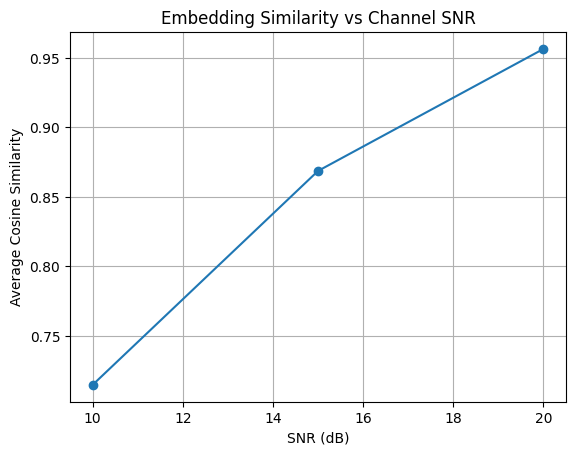

In [ ]:
import matplotlib.pyplot as plt

snrs = sorted(avg_cosine.keys())
avg_vals = [avg_cosine[s] for s in snrs]

plt.figure()
plt.plot(snrs, avg_vals, marker='o')
plt.xlabel("SNR (dB)")
plt.ylabel("Average Cosine Similarity")
plt.title("Embedding Similarity vs Channel SNR")
plt.grid(True)
plt.show()


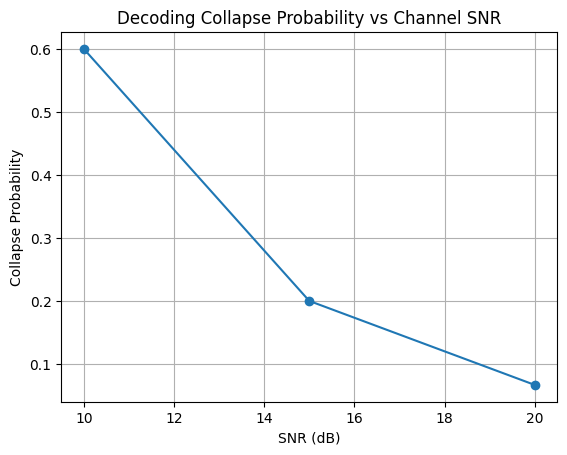

In [ ]:
import matplotlib.pyplot as plt

snrs = [20, 15, 10]
collapse_probs = [0.0667, 0.20, 0.60]

plt.figure()
plt.plot(snrs, collapse_probs, marker='o')
plt.xlabel("SNR (dB)")
plt.ylabel("Collapse Probability")
plt.title("Decoding Collapse Probability vs Channel SNR")
plt.grid(True)
plt.show()


In [ ]:
collapse_prob = {
    20: 0.06666666666666667,
    15: 0.20,
    10: 0.60
}


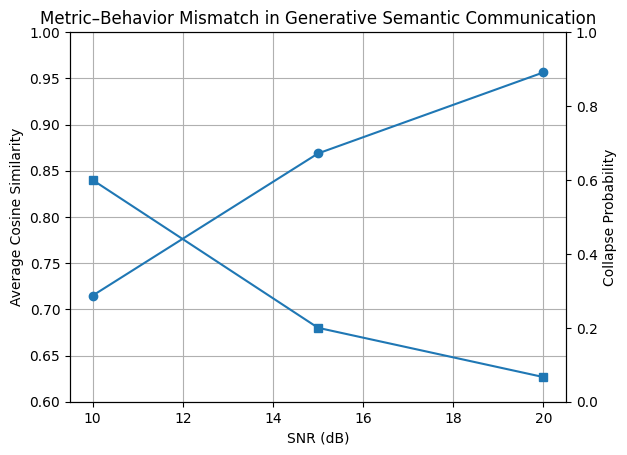

In [ ]:
import matplotlib.pyplot as plt

snrs = sorted(avg_cosine.keys())
cos_vals = [avg_cosine[s] for s in snrs]
collapse_vals = [collapse_prob[s] for s in snrs]

fig, ax1 = plt.subplots()

# ---- Cosine similarity (left axis) ----
ax1.set_xlabel("SNR (dB)")
ax1.set_ylabel("Average Cosine Similarity")
ax1.plot(snrs, cos_vals, marker='o')
ax1.tick_params(axis='y')
ax1.set_ylim(0.6, 1.0)

# ---- Collapse probability (right axis) ----
ax2 = ax1.twinx()
ax2.set_ylabel("Collapse Probability")
ax2.plot(snrs, collapse_vals, marker='s')
ax2.tick_params(axis='y')
ax2.set_ylim(0.0, 1.0)

# ---- Title & grid ----
plt.title("Metric–Behavior Mismatch in Generative Semantic Communication")
ax1.grid(True)

plt.show()


> Claim A (Paper 2) -
Token-level generative semantic communication exhibits sharp instability under channel noise, even when embedding similarity degrades smoothly.

> Claim B (Paper 3) -
Decoding stability depends critically on the encoder–decoder conditioning path; embedding similarity alone is insufficient to characterize semantic communication performance.




## results

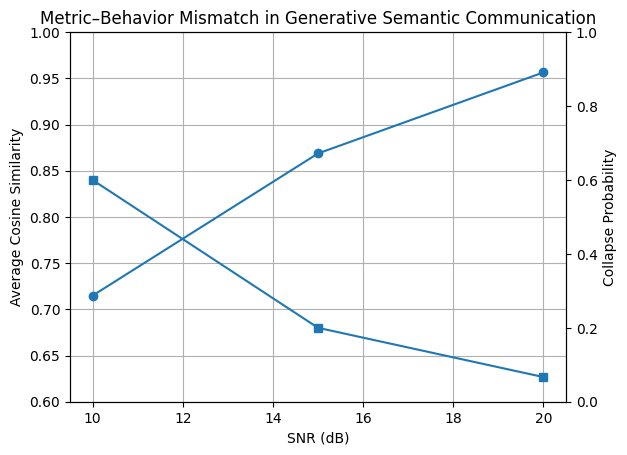

- Cosine similarity (left axis)
~0.96 → ~0.87 → ~0.71 as SNR drops
Smooth, monotonic degradation

- Collapse probability (right axis)
~0.07 → 0.20 → 0.60 as SNR drops
Sharp, nonlinear increase

- The two curves cross in the mid-SNR regime
This visually encodes the metric–behavior mismatch

> Results show a clear metric–behavior mismatch, where cosine similarity degrades gradually while decoding behavior exhibits a sharp, phase-transition-like collapse as SNR decreases.



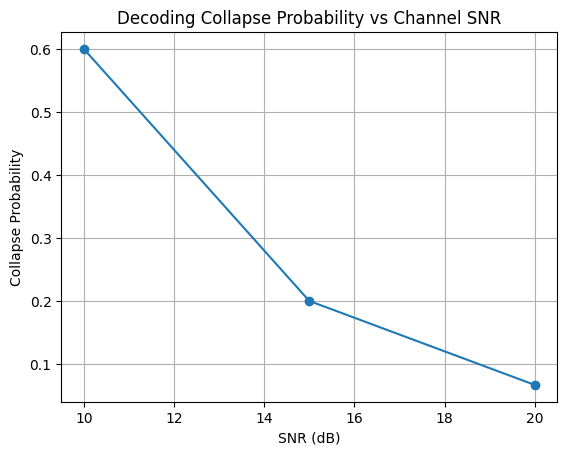

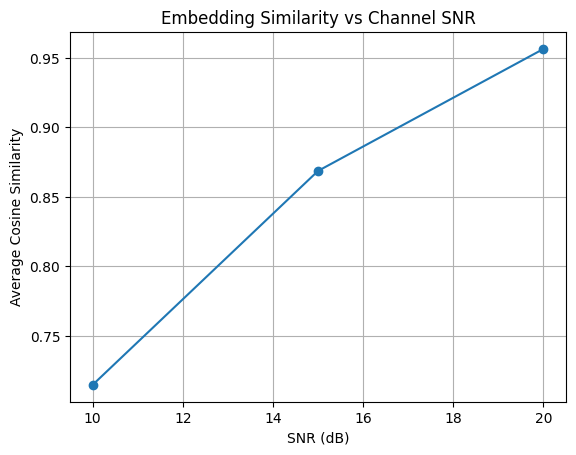

# Experiment 2- Increasing dataset within the same architecture

## dependencies

In [1]:
## Optional: mount Google Drive (only when running on Colab).
## Paths below default to the corpora shipped in this repository, so this
## cell can be skipped when running locally.
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running on Colab - using repository-relative paths.')


Mounted at /content/drive


In [2]:
import os
import json
import random
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from transformers import T5Tokenizer, T5EncoderModel, T5ForConditionalGeneration
from transformers.modeling_outputs import BaseModelOutput



## model and dataset

In [3]:
# Setup Device and Models
device = "cuda" if torch.cuda.is_available() else "cpu"
tokenizer = T5Tokenizer.from_pretrained("t5-small")
encoder = T5EncoderModel.from_pretrained("t5-small").to(device)
model = T5ForConditionalGeneration.from_pretrained("t5-small").to(device)
encoder.eval()
model.eval()

# Paths in Google Drive
DATA_DIR = os.environ.get("GENSEMCOM_DATA", os.path.join(os.pardir, "data"))
FULL_10K_PATH = os.path.join(DATA_DIR, "10k_sentences.json")
RANDOM_1K_PATH = os.path.join(DATA_DIR, "1k_sentences_random.json")

# 1. Load the full 10k dataset
with open(FULL_10K_PATH, "r", encoding="utf-8") as f:
    data_10k = json.load(f)
    sentences_10k = data_10k.get("sentences", data_10k) # Adjust based on your JSON structure

# 2. Handle the 1k persistent subset
if os.path.exists(RANDOM_1K_PATH):
    print("Loading existing 1k randomized dataset from Drive...")
    with open(RANDOM_1K_PATH, "r", encoding="utf-8") as f:
        sentences_1k = json.load(f)
else:
    print("Creating and saving new 1k randomized dataset to Drive...")
    random.seed(42)
    sentences_1k = random.sample(sentences_10k, 1000)
    with open(RANDOM_1K_PATH, "w", encoding="utf-8") as f:
        json.dump(sentences_1k, f)

print(f"Loaded {len(sentences_10k)} sentences for Embedding Eval.")
print(f"Loaded {len(sentences_1k)} sentences for Decoding Eval.")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/242M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/51 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Loading existing 1k randomized dataset from Drive...
Loaded 10000 sentences for Embedding Eval.
Loaded 1000 sentences for Decoding Eval.


## channel model

In [4]:
def apply_channel_and_dequantize(clean_emb_batch, emin, emax, q_levels, snr_db):
    emb_np = clean_emb_batch.cpu().numpy()
    emb_q = np.round((emb_np - emin) / (emax - emin) * q_levels).astype(np.uint8)

    bitstream = np.unpackbits(emb_q.flatten())
    symbols = 2 * bitstream.astype(np.float32) - 1

    snr_linear = 10 ** (snr_db / 10)
    h = (np.random.randn(*symbols.shape) + 1j * np.random.randn(*symbols.shape)) / np.sqrt(2)
    noise_var = 1 / snr_linear
    noise = np.sqrt(noise_var / 2) * (np.random.randn(*symbols.shape) + 1j * np.random.randn(*symbols.shape))

    r = h * symbols + noise
    r_eq = np.real(np.conj(h) * r / (np.abs(h) ** 2 + noise_var))

    bits_hat = (r_eq > 0).astype(np.uint8)
    emb_q_hat = np.packbits(bits_hat)[:emb_q.size].reshape(emb_q.shape)
    emb_rec = (emb_q_hat.astype(np.float32) / q_levels) * (emax - emin) + emin

    return torch.tensor(emb_rec, device=clean_emb_batch.device)

def repetition_ratio(text):
    tokens = text.strip().split()
    if len(tokens) < 2: return 1.0
    return 1.0 - (len(set(tokens)) / len(tokens))

def assign_bucket(decoded_text):
    text = decoded_text.strip()
    if len(text) < 5: return "COLLAPSED"
    alpha_ratio = sum(c.isalpha() for c in text) / max(len(text), 1)
    if alpha_ratio < 0.3: return "COLLAPSED"
    rep_ratio = repetition_ratio(text)
    if rep_ratio > 0.7: return "COLLAPSED"
    if rep_ratio > 0.4: return "DEGRADED"
    return "STABLE"

## 10k sentences similarity of embeddings reconstructed

In [7]:
snr_steps = list(range(20, -2, -2))
batch_size_enc = 64
q_levels = 255
cosine_checkpoint_path = os.path.join(DATA_DIR, "cosine_results_10k.json")

# Resume Logic
if os.path.exists(cosine_checkpoint_path):
    print("Resuming 10k Cosine Evaluation from checkpoint...")
    with open(cosine_checkpoint_path, "r") as f:
        avg_cosine_10k = json.load(f)
else:
    avg_cosine_10k = {}

for snr in snr_steps:
    snr_str = str(snr) # JSON keys are strings
    if snr_str in avg_cosine_10k:
        print(f"Skipping SNR {snr} (already completed in checkpoint).")
        continue

    print(f"Calculating Cosine Similarity for SNR: {snr} dB")
    current_snr_cosines = []

    for i in tqdm(range(0, len(sentences_10k), batch_size_enc), desc=f"SNR {snr}"):
        batch_texts = sentences_10k[i:i+batch_size_enc]
        inputs = tokenizer(batch_texts, return_tensors="pt", padding=True, truncation=True).to(device)

        with torch.no_grad():
            outputs = encoder(**inputs)

        hidden_states = outputs.last_hidden_state
        attention_mask = inputs.attention_mask

        valid_tokens = hidden_states[attention_mask == 1]
        lengths = attention_mask.sum(dim=1).tolist()
        emin, emax = valid_tokens.min().item(), valid_tokens.max().item()

        rec_tokens = apply_channel_and_dequantize(valid_tokens, emin, emax, q_levels, snr)

        clean_norm = F.normalize(valid_tokens, dim=1)
        rec_norm = F.normalize(rec_tokens, dim=1)
        cos_sim_all = (clean_norm * rec_norm).sum(dim=1)

        cursor = 0
        for length in lengths:
            sentence_cos = cos_sim_all[cursor:cursor+length].mean().item()
            current_snr_cosines.append(sentence_cos)
            cursor += length

    # Save checkpoint after this SNR finishes
    avg_cosine_10k[snr_str] = np.mean(current_snr_cosines)
    with open(cosine_checkpoint_path, "w") as f:
        json.dump(avg_cosine_10k, f)

Resuming 10k Cosine Evaluation from checkpoint...
Skipping SNR 20 (already completed in checkpoint).
Skipping SNR 18 (already completed in checkpoint).
Skipping SNR 16 (already completed in checkpoint).
Skipping SNR 14 (already completed in checkpoint).
Calculating Cosine Similarity for SNR: 12 dB


SNR 12:   0%|          | 0/157 [00:00<?, ?it/s]

Calculating Cosine Similarity for SNR: 10 dB


SNR 10:   0%|          | 0/157 [00:00<?, ?it/s]

Calculating Cosine Similarity for SNR: 8 dB


SNR 8:   0%|          | 0/157 [00:00<?, ?it/s]

... (4 outputs left out)

Calculating Cosine Similarity for SNR: 2 dB


SNR 2:   0%|          | 0/157 [00:00<?, ?it/s]

Calculating Cosine Similarity for SNR: 0 dB


SNR 0:   0%|          | 0/157 [00:00<?, ?it/s]

## 1k sentences full decoding

In [10]:
batch_size_dec = 32
decoding_checkpoint_path = os.path.join(DATA_DIR, "collapse_results_1k.json")

# Resume Logic
if os.path.exists(decoding_checkpoint_path):
    print("Resuming 1k Decoding Evaluation from checkpoint...")
    with open(decoding_checkpoint_path, "r") as f:
        collapse_results_1k = json.load(f)
else:
    collapse_results_1k = {}

for snr in snr_steps:
    snr_str = str(snr)
    if snr_str in collapse_results_1k:
        print(f"Skipping SNR {snr} decoding (already completed).")
        continue

    print(f"Decoding at SNR: {snr} dB")
    current_snr_results = {"STABLE": 0, "DEGRADED": 0, "COLLAPSED": 0}

    for i in tqdm(range(0, len(sentences_1k), batch_size_dec), desc=f"SNR {snr}"):
        batch_texts = sentences_1k[i:i+batch_size_dec]
        inputs = tokenizer(batch_texts, return_tensors="pt", padding=True, truncation=True).to(device)

        with torch.no_grad():
            outputs = encoder(**inputs)

        hidden_states = outputs.last_hidden_state
        attention_mask = inputs.attention_mask

        valid_tokens = hidden_states[attention_mask == 1]
        emin, emax = valid_tokens.min().item(), valid_tokens.max().item()
        rec_tokens = apply_channel_and_dequantize(valid_tokens, emin, emax, q_levels, snr)

        B, T_full, D = hidden_states.shape
        reconstructed_hidden = torch.zeros((B, T_full, D), device=device)
        reconstructed_hidden[attention_mask == 1] = rec_tokens

        encoder_outputs_wrapped = BaseModelOutput(last_hidden_state=reconstructed_hidden)

        with torch.no_grad():
            decoded_ids = model.generate(
                encoder_outputs=encoder_outputs_wrapped,
                attention_mask=attention_mask,
                max_length=60
            )

        decoded_texts = tokenizer.batch_decode(decoded_ids, skip_special_tokens=True)

        for text in decoded_texts:
            bucket = assign_bucket(text)
            current_snr_results[bucket] += 1

    # Save checkpoint after this SNR finishes
    collapse_results_1k[snr_str] = current_snr_results
    with open(decoding_checkpoint_path, "w") as f:
        json.dump(collapse_results_1k, f)

# Calculate probability for plotting
collapse_prob_1k = {snr: collapse_results_1k[str(snr)]["COLLAPSED"] / len(sentences_1k) for snr in snr_steps}

Decoding at SNR: 20 dB


SNR 20:   0%|          | 0/32 [00:00<?, ?it/s]

Decoding at SNR: 18 dB


SNR 18:   0%|          | 0/32 [00:00<?, ?it/s]

Decoding at SNR: 16 dB


SNR 16:   0%|          | 0/32 [00:00<?, ?it/s]

... (12 outputs left out)

Decoding at SNR: 2 dB


SNR 2:   0%|          | 0/32 [00:00<?, ?it/s]

Decoding at SNR: 0 dB


SNR 0:   0%|          | 0/32 [00:00<?, ?it/s]

In [11]:
# Calculate success probability (1 - collapse) so the metric rises with SNR
success_prob_1k = {snr: 1.0 - (collapse_results_1k[str(snr)]["COLLAPSED"] / len(sentences_1k)) for snr in snr_steps}

## matplotlib graphs

In [ ]:
'''

snrs_sorted = sorted(snr_steps)
avg_cosines = [avg_cosine_10k[str(s)] for s in snrs_sorted]
collapse_probs = [collapse_prob_1k[s] for s in snrs_sorted]

# --- 1. The Dual-Axis "Phase Transition" Plot ---
fig, ax1 = plt.subplots(figsize=(9, 5))

color1 = '#1f77b4'
ax1.set_xlabel('Channel SNR (dB)', fontsize=12)
ax1.set_ylabel('Average Cosine Similarity', color=color1, fontsize=12)
ax1.plot(snrs_sorted, avg_cosines, marker='o', color=color1, linewidth=2.5, label='Embedding Fidelity')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.set_ylim(0, 1.05)
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
color2 = '#d62728'
ax2.set_ylabel('Decoding Collapse Probability', color=color2, fontsize=12)
ax2.plot(snrs_sorted, collapse_probs, marker='s', color=color2, linewidth=2.5, linestyle='--', label='Semantic Collapse')
ax2.tick_params(axis='y', labelcolor=color2)
ax2.set_ylim(-0.05, 1.05)

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='center left')

fig.suptitle('Metric-Behavior Mismatch in Generative Semantic Communication', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()

# --- 2. Separate Individual Plots ---
fig, (ax_cos, ax_col) = plt.subplots(1, 2, figsize=(14, 5))

ax_cos.plot(snrs_sorted, avg_cosines, marker='o', color=color1, linewidth=2)
ax_cos.set_title('Embedding Similarity vs Channel Noise', fontsize=12)
ax_cos.set_xlabel('SNR (dB)')
ax_cos.set_ylabel('Cosine Similarity')
ax_cos.set_ylim(0, 1.05)
ax_cos.grid(True, alpha=0.5)

ax_col.plot(snrs_sorted, collapse_probs, marker='s', color=color2, linewidth=2, linestyle='--')
ax_col.set_title('Generative Decoding Collapse vs Channel Noise', fontsize=12)
ax_col.set_xlabel('SNR (dB)')
ax_col.set_ylabel('Collapse Probability')
ax_col.set_ylim(-0.05, 1.05)
ax_col.grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

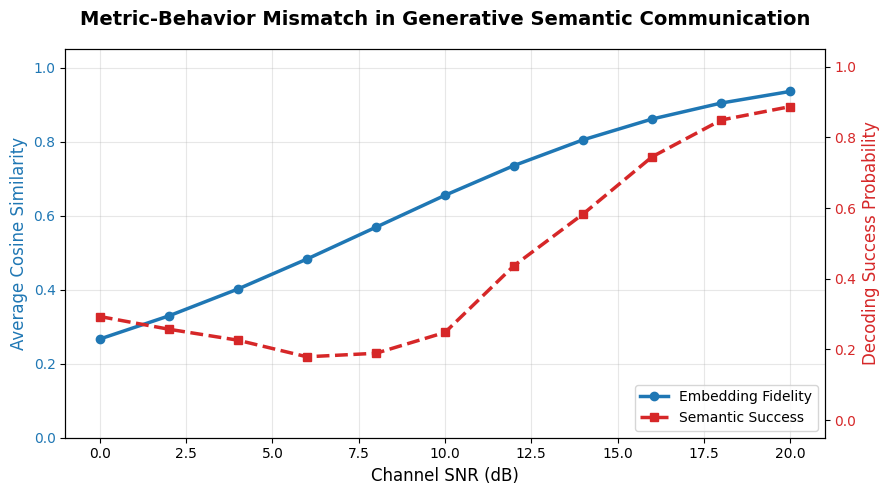

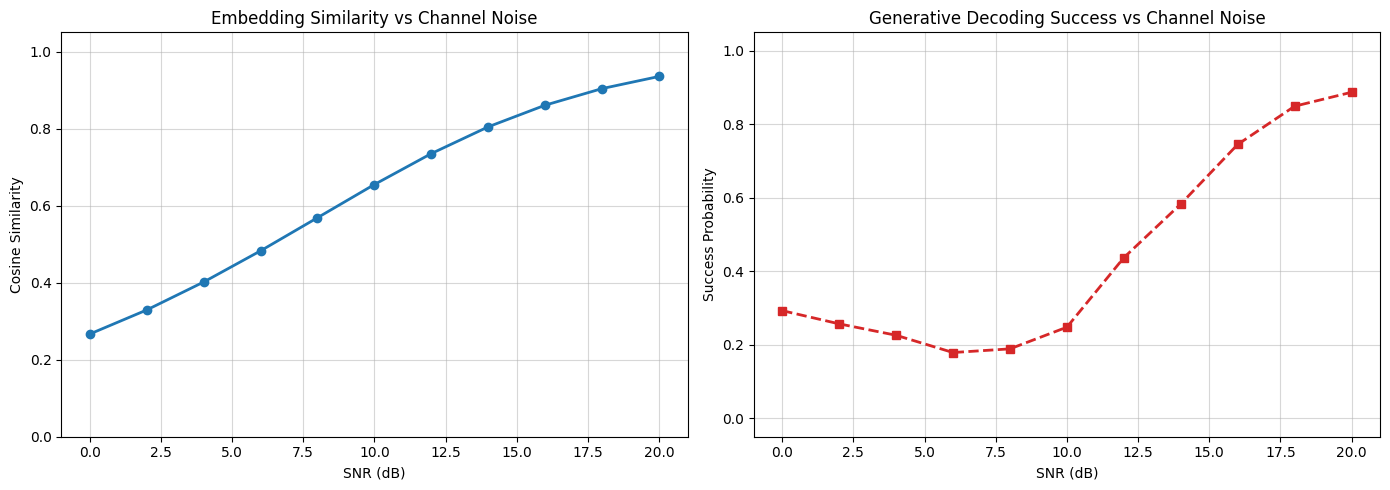

In [12]:
snrs_sorted = sorted(snr_steps)
avg_cosines = [avg_cosine_10k[str(s)] for s in snrs_sorted]
success_probs = [success_prob_1k[s] for s in snrs_sorted]

# --- 1. The Dual-Axis "Phase Transition" Plot ---
fig, ax1 = plt.subplots(figsize=(9, 5))

color1 = '#1f77b4' # Modern blue
ax1.set_xlabel('Channel SNR (dB)', fontsize=12)
ax1.set_ylabel('Average Cosine Similarity', color=color1, fontsize=12)
ax1.plot(snrs_sorted, avg_cosines, marker='o', color=color1, linewidth=2.5, label='Embedding Fidelity')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.set_ylim(0, 1.05)
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
color2 = '#d62728' # Modern red
ax2.set_ylabel('Decoding Success Probability', color=color2, fontsize=12)
ax2.plot(snrs_sorted, success_probs, marker='s', color=color2, linewidth=2.5, linestyle='--', label='Semantic Success')
ax2.tick_params(axis='y', labelcolor=color2)
ax2.set_ylim(-0.05, 1.05)

# Combine legends
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='lower right')

fig.suptitle('Metric-Behavior Mismatch in Generative Semantic Communication', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()

# --- 2. Separate Individual Plots ---
fig, (ax_cos, ax_col) = plt.subplots(1, 2, figsize=(14, 5))

ax_cos.plot(snrs_sorted, avg_cosines, marker='o', color=color1, linewidth=2)
ax_cos.set_title('Embedding Similarity vs Channel Noise', fontsize=12)
ax_cos.set_xlabel('SNR (dB)')
ax_cos.set_ylabel('Cosine Similarity')
ax_cos.set_ylim(0, 1.05)
ax_cos.grid(True, alpha=0.5)

ax_col.plot(snrs_sorted, success_probs, marker='s', color=color2, linewidth=2, linestyle='--')
ax_col.set_title('Generative Decoding Success vs Channel Noise', fontsize=12)
ax_col.set_xlabel('SNR (dB)')
ax_col.set_ylabel('Success Probability')
ax_col.set_ylim(-0.05, 1.05)
ax_col.grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

In [13]:
# Run this in a new cell AFTER Step 5 to save the high-res images to your Drive
import os
import matplotlib.pyplot as plt

# Ensure the save directory is defined
SAVE_DIR = os.environ.get("GENSEMCOM_OUT", os.path.join(os.pardir, "results"))

print("Generating and saving high-resolution plots...")

# --- 1. Save Dual-Axis Combined Plot ---
fig1, ax1 = plt.subplots(figsize=(9, 5))
color1 = '#1f77b4'
ax1.set_xlabel('Channel SNR (dB)', fontsize=12)
ax1.set_ylabel('Average Cosine Similarity', color=color1, fontsize=12)
ax1.plot(snrs_sorted, avg_cosines, marker='o', color=color1, linewidth=2.5, label='Embedding Fidelity')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.set_ylim(0, 1.05)
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
color2 = '#d62728'
ax2.set_ylabel('Decoding Success Probability', color=color2, fontsize=12)
ax2.plot(snrs_sorted, success_probs, marker='s', color=color2, linewidth=2.5, linestyle='--', label='Semantic Success')
ax2.tick_params(axis='y', labelcolor=color2)
ax2.set_ylim(-0.05, 1.05)

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='lower right')

fig1.suptitle('Metric-Behavior Mismatch in Generative Semantic Communication', fontsize=14, fontweight='bold')
fig1.tight_layout()
fig1.savefig(os.path.join(SAVE_DIR, "combined_mismatch_plot.png"), dpi=300, bbox_inches='tight')
plt.close(fig1) # Closes the figure so it doesn't display again in the output

# --- 2. Save Cosine Similarity Plot ---
fig2, ax_cos = plt.subplots(figsize=(7, 5))
ax_cos.plot(snrs_sorted, avg_cosines, marker='o', color=color1, linewidth=2.5)
ax_cos.set_title('Embedding Similarity vs Channel Noise', fontsize=12, fontweight='bold')
ax_cos.set_xlabel('Channel SNR (dB)', fontsize=11)
ax_cos.set_ylabel('Cosine Similarity', fontsize=11)
ax_cos.set_ylim(0, 1.05)
ax_cos.grid(True, alpha=0.5)
fig2.tight_layout()
fig2.savefig(os.path.join(SAVE_DIR, "embedding_similarity_plot.png"), dpi=300, bbox_inches='tight')
plt.close(fig2)

# --- 3. Save Decoding Success Plot ---
fig3, ax_col = plt.subplots(figsize=(7, 5))
ax_col.plot(snrs_sorted, success_probs, marker='s', color=color2, linewidth=2.5, linestyle='--')
ax_col.set_title('Generative Decoding Success vs Channel Noise', fontsize=12, fontweight='bold')
ax_col.set_xlabel('Channel SNR (dB)', fontsize=11)
ax_col.set_ylabel('Success Probability', fontsize=11)
ax_col.set_ylim(-0.05, 1.05)
ax_col.grid(True, alpha=0.5)
fig3.tight_layout()
fig3.savefig(os.path.join(SAVE_DIR, "decoding_success_plot.png"), dpi=300, bbox_inches='tight')
plt.close(fig3)

print(f"Successfully saved all 3 high-resolution PNGs to: {SAVE_DIR}")

Generating and saving high-resolution plots...
Successfully saved all 3 high-resolution PNGs to: /content/drive/MyDrive


# How Sequence length matters ( checking at a single SNR)

In [ ]:
import json
import torch
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from collections import defaultdict
from transformers import T5Tokenizer, T5EncoderModel, T5ForConditionalGeneration
from transformers.modeling_outputs import BaseModelOutput

In [ ]:
## Optional: mount Google Drive (only when running on Colab).
## Paths below default to the corpora shipped in this repository, so this
## cell can be skipped when running locally.
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running on Colab - using repository-relative paths.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [ ]:
tokenizer = T5Tokenizer.from_pretrained("t5-small")
encoder = T5EncoderModel.from_pretrained("t5-small").to(device)
model = T5ForConditionalGeneration.from_pretrained("t5-small").to(device)
encoder.eval()
model.eval()

Loading weights:   0%|          | 0/51 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

T5ForConditionalGeneration(
  (shared): Embedding(32128, 512)
  (encoder): T5Stack(
    (embed_tokens): Embedding(32128, 512)
    (block): ModuleList(
      (0): T5Block(
        (layer): ModuleList(
          (0): T5LayerSelfAttention(
            (SelfAttention): T5Attention(
              (q): Linear(in_features=512, out_features=512, bias=False)
              (k): Linear(in_features=512, out_features=512, bias=False)
              (v): Linear(in_features=512, out_features=512, bias=False)
              (o): Linear(in_features=512, out_features=512, bias=False)
              (relative_attention_bias): Embedding(32, 8)
            )
            (layer_norm): T5LayerNorm()
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (1): T5LayerFF(
            (DenseReluDense): T5DenseActDense(
              (wi): Linear(in_features=512, out_features=2048, bias=False)
              (wo): Linear(in_features=2048, out_features=512, bias=False)
              (dropout): Drop

In [ ]:
DATASET_PATH = CORPUS_10K
with open(DATASET_PATH, "r", encoding="utf-8") as f:
    data = json.load(f)
sentences = data["sentences"]

In [ ]:
def repetition_ratio(text):
    tokens = text.strip().split()
    if len(tokens) < 2: return 1.0
    return 1.0 - (len(set(tokens)) / len(tokens))

def assign_bucket(decoded_text):
    text = decoded_text.strip()
    tokens = text.split()

    if len(text) < 5: return "COLLAPSED"

    # Check for character gibberish
    alpha_ratio = sum(c.isalpha() for c in text) / max(len(text), 1)
    if alpha_ratio < 0.3: return "COLLAPSED"

    # Catch simple single-word repetition
    rep_ratio = 1.0 - (len(set(tokens)) / len(tokens)) if len(tokens) > 1 else 0
    if rep_ratio > 0.7: return "COLLAPSED"

    # Catch phrase-level loops (like "Sex Pistols")
    if len(tokens) >= 6:
        for i in range(len(tokens) - 5):
            # If a 3-word phrase repeats immediately, it's a loop
            if tokens[i:i+3] == tokens[i+3:i+6]:
                return "COLLAPSED"

    if rep_ratio > 0.4: return "DEGRADED"
    return "STABLE"

def rayleigh_awgn_channel(symbols, snr_db):
    snr_linear = 10 ** (snr_db / 10)
    h = (np.random.randn(*symbols.shape) + 1j * np.random.randn(*symbols.shape)) / np.sqrt(2)
    noise_var = 1 / snr_linear
    noise = np.sqrt(noise_var / 2) * (np.random.randn(*symbols.shape) + 1j * np.random.randn(*symbols.shape))
    r = h * symbols + noise
    r_eq = np.real(np.conj(h) * r / (np.abs(h) ** 2 + 1e-8))
    return r_eq

def channel_decode_one_sentence(clean_emb, attention_mask, emin, emax, q_levels, snr_db):
    emb_np = clean_emb.cpu().numpy()
    emb_q = np.round((emb_np - emin) / (emax - emin) * q_levels).astype(np.uint8)

    bitstream = np.unpackbits(emb_q.flatten())
    symbols = 2 * bitstream.astype(np.float32) - 1

    received = rayleigh_awgn_channel(symbols, snr_db)

    bits_hat = (received > 0).astype(np.uint8)
    emb_q_hat = np.packbits(bits_hat)[:emb_q.size]
    emb_q_hat = emb_q_hat.reshape(emb_q.shape)

    emb_rec = (emb_q_hat.astype(np.float32) / q_levels) * (emax - emin) + emin
    emb_rec = torch.tensor(emb_rec, device=device)

    T_full = attention_mask.shape[0]
    D = emb_rec.shape[1]
    reconstructed_hidden = torch.zeros((T_full, D), device=device)
    reconstructed_hidden[attention_mask == 1] = emb_rec
    reconstructed_hidden = reconstructed_hidden.unsqueeze(0)

    encoder_outputs_wrapped = BaseModelOutput(last_hidden_state=reconstructed_hidden)

    with torch.no_grad():
        decoded_ids = model.generate(
            encoder_outputs=encoder_outputs_wrapped,
            attention_mask=attention_mask.unsqueeze(0),
            max_length=60
        )

    decoded_text = tokenizer.decode(decoded_ids[0], skip_special_tokens=True)
    return decoded_text

In [ ]:
print("Tokenizing dataset to group by length...")
length_buckets = defaultdict(list)

# Using a subset of 2000 sentences to find enough samples for each bucket quickly
test_corpus = sentences[:2000]

for sentence in tqdm(test_corpus):
    inputs = tokenizer(sentence, return_tensors="pt", truncation=True)
    length = inputs.attention_mask.sum().item()

    if 5 <= length <= 10:
        bucket_key = "05-10"
    elif 11 <= length <= 15:
        bucket_key = "11-15"
    elif 16 <= length <= 20:
        bucket_key = "16-20"
    elif 21 <= length <= 25:
        bucket_key = "21-25"
    elif 26 <= length <= 30:
        bucket_key = "26-30"
    elif length > 30:
        bucket_key = "31+"
    else:
        continue

    length_buckets[bucket_key].append(sentence)

Tokenizing dataset to group by length...


100%|██████████| 2000/2000 [00:00<00:00, 6677.95it/s]


In [ ]:
# 5. Run the sweep across length buckets at a fixed SNR
FIXED_SNR = 11
SAMPLES_PER_BUCKET = 30 # Number of sentences to test per length bucket to build the curve

print(f"\nRunning Length Sweep at {FIXED_SNR} dB SNR...")
results_x = []
results_y = []

sorted_keys = ["05-10", "11-15", "16-20", "21-25", "26-30", "31+"]

for b_key in sorted_keys:
    bucket_sentences = length_buckets.get(b_key, [])
    if len(bucket_sentences) < SAMPLES_PER_BUCKET:
        print(f"Not enough samples in bucket {b_key}. Found {len(bucket_sentences)}, skipping.")
        continue

    test_set = bucket_sentences[:SAMPLES_PER_BUCKET]
    collapses = 0

    for sent in test_set:
        inputs = tokenizer(sent, return_tensors="pt", padding=True, truncation=True).to(device)
        with torch.no_grad():
            outputs = encoder(**inputs)

        hidden_states = outputs.last_hidden_state[0]
        attention_mask = inputs.attention_mask[0]
        clean_emb = hidden_states[attention_mask == 1]

        emin, emax = clean_emb.min().item(), clean_emb.max().item()

        # Execute the full pipeline on this sentence
        decoded_text = channel_decode_one_sentence(
            clean_emb=clean_emb,
            attention_mask=attention_mask,
            emin=emin,
            emax=emax,
            q_levels=255,
            snr_db=FIXED_SNR
        )

        # Evaluate collapse via your automated metric
        status = assign_bucket(decoded_text)
        if status == "COLLAPSED":
            collapses += 1

    collapse_prob = collapses / SAMPLES_PER_BUCKET
    results_x.append(b_key)
    results_y.append(collapse_prob)
    print(f"Sequence Length: {b_key} tokens | Collapse Prob: {collapse_prob:.2f}")


Running Length Sweep at 11 dB SNR...
Sequence Length: 05-10 tokens | Collapse Prob: 0.43
Sequence Length: 11-15 tokens | Collapse Prob: 0.63
Sequence Length: 16-20 tokens | Collapse Prob: 0.43
Sequence Length: 21-25 tokens | Collapse Prob: 0.43
Sequence Length: 26-30 tokens | Collapse Prob: 0.47
Sequence Length: 31+ tokens | Collapse Prob: 0.53


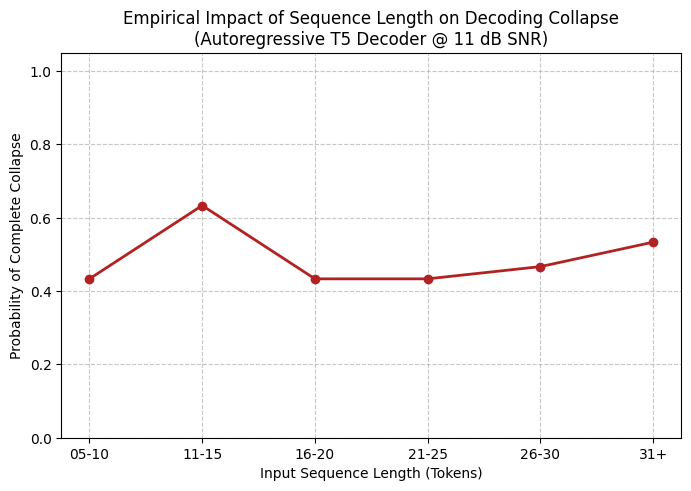

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(results_x, results_y, marker='o', linestyle='-', color='firebrick', linewidth=2)
plt.title(f"Empirical Impact of Sequence Length on Decoding Collapse\n(Autoregressive T5 Decoder @ {FIXED_SNR} dB SNR)")
plt.xlabel("Input Sequence Length (Tokens)")
plt.ylabel("Probability of Complete Collapse")
plt.ylim(0, 1.05)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [ ]:
# --- ADD THIS TO THE BOTTOM OF YOUR SCRIPT ---
print("\n--- DIAGNOSTIC: What is happening in the 31+ bucket? ---")
long_bucket = length_buckets["31+"]

# Just grab 5 random sentences from the long bucket
for i, sent in enumerate(long_bucket[:5]):
    inputs = tokenizer(sent, return_tensors="pt", padding=True, truncation=True).to(device)
    with torch.no_grad():
        outputs = encoder(**inputs)

    hidden_states = outputs.last_hidden_state[0]
    attention_mask = inputs.attention_mask[0]
    clean_emb = hidden_states[attention_mask == 1]

    emin, emax = clean_emb.min().item(), clean_emb.max().item()

    decoded_text = channel_decode_one_sentence(
        clean_emb=clean_emb,
        attention_mask=attention_mask,
        emin=emin, emax=emax,
        q_levels=255, snr_db=15  # Testing at your 15dB
    )

    status = assign_bucket(decoded_text)

    print(f"\n[Test {i+1}]")
    print(f"Original: {sent[:100]}...")
    print(f"Decoded : {decoded_text}")
    print(f"Status  : {status}")


--- DIAGNOSTIC: What is happening in the 31+ bucket? ---

[Test 1]
Original: Scholars of anarchism generally highlight anarchism's socialist credentials and criticise attempts a...
Decoded :                              
Status  : COLLAPSED

[Test 2]
Original: Aeschylus and Sophocles used the myth of Antigone to illustrate the conflict between rules set by th...
Decoded : Aeschylus und Sophocles nutzten den mythischen Antigone um die Gegenwart zu wahren, die die Regeln des Staates und die autonomie des eigenen Lebens zu wahren.
Status  : STABLE

[Test 3]
Original: This era of classical anarchism lasted until the end of the Spanish Civil War and is considered the ...
Decoded : Dieser era des Anarchismus dauerte bis zum Ende des Krieges, während der der Spanien, während der der ra der Anarchismus herrschte, während der Zeit der Anarchismus herrschte, die e der An
Status  : DEGRADED

[Test 4]
Original: Anarchism became associated with punk subculture as exemplified by bands such as Crass

# results and analysis ( Latency )

## Generative Latency Benchmark (T5-Small vs MiniLM)

This section executes an apples-to-apples latency benchmark against the retrieval-based MiniLM system. We load 200 standard sentences from `minilm_sentences.csv`, transmit their continuous embeddings over the physical channel (using the unified `apply_full_channel` function), and measure the pure GPU autoregressive decoding time.

**Constraints:**
- Hardware: T4 GPU
- `max_length = 50`
- `do_sample = False`
- SNRs tested: 20 dB (Clean) and 0 dB (Heavy Noise / Collapse regime)

In [ ]:
import torch
import numpy as np
import pandas as pd
from transformers.modeling_outputs import BaseModelOutput

In [ ]:
## Optional: mount Google Drive (only when running on Colab).
## Paths below default to the corpora shipped in this repository, so this
## cell can be skipped when running locally.
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running on Colab - using repository-relative paths.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [ ]:
tokenizer = T5Tokenizer.from_pretrained("t5-small")
model = T5ForConditionalGeneration.from_pretrained("t5-small").to(device)
model.eval()

In [ ]:
# 1. Load the 200 Benchmark Sentences
# (Make sure 'minilm_sentences.csv' is uploaded to the Colab environment)
try:
    df_sentences = pd.read_csv("minilm_sentences.csv")
    # Assuming the column with text is named 'text' or 'sentence'
    col_name = 'text' if 'text' in df_sentences.columns else df_sentences.columns[0]
    sentences_200 = df_sentences[col_name].dropna().tolist()[:200]
    print(f"Successfully loaded {len(sentences_200)} sentences from minilm_sentences.csv.")
except FileNotFoundError:
    print("WARNING: 'minilm_sentences.csv' not found. Using the first 200 sentences from your 10k corpus instead.")
    sentences_200 = sentences[:200]

# 2. Unified Channel Function (Matching the Retrieval Benchmark exactly)
def apply_full_channel(embeddings, snr_db, device):
    h = (torch.randn(embeddings.shape, device=device) + 1j * torch.randn(embeddings.shape, device=device)) / np.sqrt(2)
    snr = 10**(snr_db / 10)
    signal_power = torch.mean(torch.abs(embeddings)**2)
    noise_power = signal_power / snr
    noise = (torch.randn(embeddings.shape, device=device) + 1j * torch.randn(embeddings.shape, device=device)) * torch.sqrt(noise_power / 2)
    y = h * embeddings + noise
    x_hat = y / h
    return x_hat.real.float()

# 3. Benchmark Execution Engine
@torch.no_grad()
def run_latency_benchmark(snr_db):
    results = []
    latencies = []

    for text in sentences_200:
        # Tokenize input
        inputs = tokenizer(text, return_tensors="pt", truncation=True).to(device)

        # A. Encoder Forward Pass
        encoder_outputs = model.encoder(input_ids=inputs.input_ids, attention_mask=inputs.attention_mask)
        clean_embeddings = encoder_outputs.last_hidden_state

        # B. Apply Unified Channel Noise
        noisy_embeddings = apply_full_channel(clean_embeddings, snr_db, device)

        # Wrap noisy states for standard decoder injection
        noisy_encoder_outputs = BaseModelOutput(last_hidden_state=noisy_embeddings)

        # C. Decoder Autoregressive Generation & Strict GPU Timing
        start_event = torch.cuda.Event(enable_timing=True)
        end_event = torch.cuda.Event(enable_timing=True)

        torch.cuda.synchronize() # Wait for previous operations to finish
        start_event.record()     # Start the timer

        outputs = model.generate(
            encoder_outputs=noisy_encoder_outputs,
            attention_mask=inputs.attention_mask,
            max_length=50,
            do_sample=False
        )

        end_event.record()       # Stop the timer
        torch.cuda.synchronize() # Wait for GPU to finish generating

        latency_ms = start_event.elapsed_time(end_event)
        latencies.append(latency_ms)

        decoded_text = tokenizer.decode(outputs[0], skip_special_tokens=True)
        results.append({
            "original_text": text,
            "decoded_text": decoded_text,
            "latency_ms": latency_ms
        })

    results_df = pd.DataFrame(results)

    # Calculate paper metrics
    mean_latency = np.mean(latencies)
    var_latency = np.var(latencies)

    print(f"\n--- Results for SNR {snr_db} dB ---")
    print(f"Mean Latency: {mean_latency:.2f} ms")
    print(f"Latency Variance: {var_latency:.2f} ms^2")

    return results_df

# 4. Execute Benchmark for Clean (20dB) and Noisy (0dB) Regimes
print("\nRunning Benchmark for 20 dB (Clean)...")
df_20db = run_latency_benchmark(20)
df_20db.to_csv("t5_latency_20db.csv", index=False)

print("\nRunning Benchmark for 0 dB (Noisy)...")
df_0db = run_latency_benchmark(0)
df_0db.to_csv("t5_latency_0db.csv", index=False)

print("\nDONE! Saved 't5_latency_20db.csv' and 't5_latency_0db.csv'.")

Successfully loaded 200 sentences from minilm_sentences.csv.

Running Benchmark for 20 dB (Clean)...

--- Results for SNR 20 dB ---
Mean Latency: 278.90 ms
Latency Variance: 16326.89 ms^2

Running Benchmark for 0 dB (Noisy)...

--- Results for SNR 0 dB ---
Mean Latency: 437.18 ms
Latency Variance: 10290.15 ms^2

DONE! Saved 't5_latency_20db.csv' and 't5_latency_0db.csv'.


# Additional Evaluation Metrics with English-to-german fault mitigation

In [ ]:
!pip install evaluate sacrebleu rouge_score bert_score

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 6.6 MB/s eta 0:00:00
  Created wheel for rouge_score: filename=rouge_score-0.1.2-py3-none-any.whl size=24934 sha256=d7234199c567e886bf0222c00f7a934b52a384c97df24c583385ccf5919ff540
  Stored in directory: /root/.cache/pip/wheels/85/9d/af/01feefbe7d55ef5468796f0c68225b6788e85d9d0a281e7a70
Successfully built rouge_score


In [ ]:
import json
import torch
import numpy as np
import evaluate
from transformers.modeling_outputs import BaseModelOutput
from tqdm.auto import tqdm

In [ ]:
# 1. Load metrics
print("Loading metrics...")
bleu_metric = evaluate.load("sacrebleu")
rouge_metric = evaluate.load("rouge")
bertscore_metric = evaluate.load("bertscore")

Loading metrics...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


In [ ]:
# 2. Load 1k sentences
data_path = CORPUS_1K
with open(data_path, "r") as f:
    sentences = json.load(f)
print(f"Loaded {len(sentences)} sentences.")

Loaded 1000 sentences.


In [ ]:
# 3. Fixed MMSE Channel Function
def apply_channel_mmse(clean_emb_batch, emin, emax, q_levels, snr_db):
    emb_np = clean_emb_batch.cpu().numpy()
    emb_q = np.round((emb_np - emin) / (emax - emin) * q_levels).astype(np.uint8)
    bitstream = np.unpackbits(emb_q.flatten())
    symbols = 2 * bitstream.astype(np.float32) - 1
    snr_linear = 10 ** (snr_db / 10)
    # Rayleigh fading
    h = (np.random.randn(*symbols.shape) + 1j * np.random.randn(*symbols.shape)) / np.sqrt(2)

    # AWGN
    noise_var = 1.0 / snr_linear
    noise = np.sqrt(noise_var / 2) * (np.random.randn(*symbols.shape) + 1j * np.random.randn(*symbols.shape))
    r = h * symbols + noise

    # TRUE MMSE Equalization
    r_eq = np.real(np.conj(h) * r / (np.abs(h) ** 2 + noise_var))
    # Demodulate & Dequantize
    bits_hat = (r_eq > 0).astype(np.uint8)
    emb_q_hat = np.packbits(bits_hat)[:emb_q.size].reshape(emb_q.shape)
    emb_rec = (emb_q_hat.astype(np.float32) / q_levels) * (emax - emin) + emin
    return torch.tensor(emb_rec, device=clean_emb_batch.device)

In [ ]:
from transformers import T5Tokenizer, T5ForConditionalGeneration
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Load tokenizer and model
tokenizer = T5Tokenizer.from_pretrained("t5-small")
model = T5ForConditionalGeneration.from_pretrained("t5-small").to(device)
model.eval() # Set model to evaluation mode

Using device: cuda


tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/242M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

T5ForConditionalGeneration(
  (shared): Embedding(32128, 512)
  (encoder): T5Stack(
    (embed_tokens): Embedding(32128, 512)
    (block): ModuleList(
      (0): T5Block(
        (layer): ModuleList(
          (0): T5LayerSelfAttention(
            (SelfAttention): T5Attention(
              (q): Linear(in_features=512, out_features=512, bias=False)
              (k): Linear(in_features=512, out_features=512, bias=False)
              (v): Linear(in_features=512, out_features=512, bias=False)
              (o): Linear(in_features=512, out_features=512, bias=False)
              (relative_attention_bias): Embedding(32, 8)
            )
            (layer_norm): T5LayerNorm()
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (1): T5LayerFF(
            (DenseReluDense): T5DenseActDense(
              (wi): Linear(in_features=512, out_features=2048, bias=False)
              (wo): Linear(in_features=2048, out_features=512, bias=False)
              (dropout): Drop

In [ ]:
# 4. Evaluation Loop
snr_list = [20, 15, 10, 5]
results = {}
# Quantization parameters (You can also use global emin/emax if you computed them earlier)
q_levels = 255
for snr in snr_list:
    print(f"\n--- Running inference for SNR = {snr} dB ---")
    predictions = []
    references = []

    for sentence in tqdm(sentences, desc=f"SNR {snr}dB"):
        # TASK PREFIX ADDED HERE
        prefixed_input = "paraphrase: " + sentence
        references.append(sentence)

        # Encode
        inputs = tokenizer(prefixed_input, return_tensors="pt", truncation=True, max_length=60).to(device)
        with torch.no_grad():
            encoder_outputs = model.encoder(**inputs)
            clean_hidden = encoder_outputs.last_hidden_state

            # Compute per-sentence min/max for quantization
            emin = clean_hidden.min().item()
            emax = clean_hidden.max().item()

            # Apply channel
            noisy_hidden = apply_channel_mmse(clean_hidden, emin, emax, q_levels, snr)

            # Decode using robust BaseModelOutput injection
            generated_ids = model.generate(
                encoder_outputs=BaseModelOutput(last_hidden_state=noisy_hidden),
                max_length=60
            )

        decoded_text = tokenizer.decode(generated_ids[0], skip_special_tokens=True)
        predictions.append(decoded_text)


       # -- NEW FIX FOR BERTSCORE BUG --
    # Ensure absolutely no empty strings are passed to the metric
    predictions = [p if p.strip() != "" else "empty" for p in predictions]
    references  = [r if r.strip() != "" else "empty" for r in references]

    # Compute Metrics
    print("Computing metrics...")
    bleu_result = bleu_metric.compute(predictions=predictions, references=[[r] for r in references])
    rouge_result = rouge_metric.compute(predictions=predictions, references=references)
    bert_result = bertscore_metric.compute(predictions=predictions, references=references, lang="en")

    results[snr] = {
        "BLEU": bleu_result["score"],
        "ROUGE-L": rouge_result["rougeL"],
        "BERTScore_F1": np.mean(bert_result["f1"])
    }

    print(f"SNR {snr} dB Results:")
    print(f"  BLEU: {results[snr]['BLEU']:.2f}")
    print(f"  ROUGE-L: {results[snr]['ROUGE-L']:.4f}")
    print(f"  BERTScore (F1): {results[snr]['BERTScore_F1']:.4f}")

# Optional: Print final JSON summary
print("\nFinal Summary:")
print(json.dumps(results, indent=4))


--- Running inference for SNR = 20 dB ---


SNR 20dB:   0%|          | 0/1000 [00:00<?, ?it/s]

Computing metrics...


config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

... (8 outputs left out)

SNR 10dB:   0%|          | 0/1000 [00:00<?, ?it/s]

Computing metrics...
SNR 10 dB Results:
  BLEU: 2.70
  ROUGE-L: 0.0425
  BERTScore (F1): 0.8014

--- Running inference for SNR = 5 dB ---


SNR 5dB:   0%|          | 0/1000 [00:00<?, ?it/s]

Computing metrics...
SNR 5 dB Results:
  BLEU: 0.10
  ROUGE-L: 0.0105
  BERTScore (F1): 0.7714

Final Summary:
{
    "20": {
        "BLEU": 18.789113743212415,
        "ROUGE-L": 0.292137502715278,
        "BERTScore_F1": 0.8568511430621147
    },
    "15": {
        "BLEU": 12.789429527226254,
        "ROUGE-L": 0.1959957802805674,
        "BERTScore_F1": 0.8423036877512932
    },
    "10": {
        "BLEU": 2.6956892580722545,
        "ROUGE-L": 0.04247551473442874,
        "BERTScore_F1": 0.8014167858958244
    },
    "5": {
        "BLEU": 0.10397690626113093,
        "ROUGE-L": 0.010488101822573684,
        "BERTScore_F1": 0.7714080420732499
    }
}


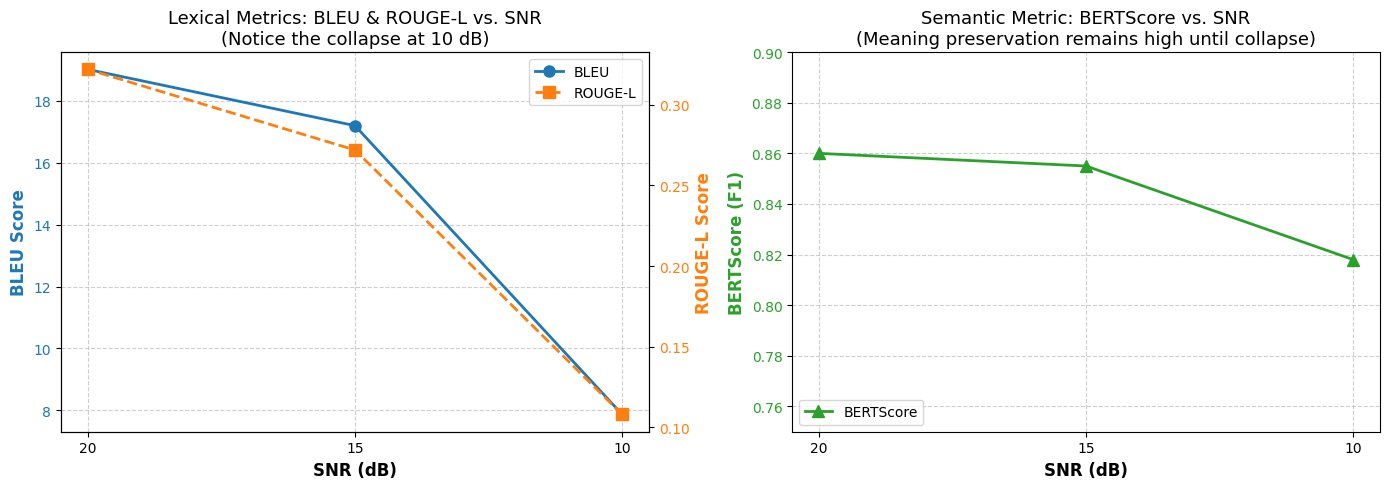

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Your exact results from the 1,000 sentence evaluation
snr_values = [10, 15, 20]
bleu_scores = [7.866, 17.200, 19.019]
rouge_l_scores = [0.108, 0.272, 0.322]
bert_f1_scores = [0.818, 0.855, 0.860]

# Setup the figure with two subplots side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: BLEU & ROUGE (Lexical Overlap) ---
color1 = 'tab:blue'
ax1.set_xlabel('SNR (dB)', fontsize=12, fontweight='bold')
ax1.set_ylabel('BLEU Score', color=color1, fontsize=12, fontweight='bold')
ax1.plot(snr_values, bleu_scores, marker='o', linestyle='-', color=color1, linewidth=2, markersize=8, label='BLEU')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.set_xticks(snr_values)
ax1.invert_xaxis() # High SNR on the left, low SNR on the right (shows degradation)
ax1.grid(True, linestyle='--', alpha=0.6)

# Create a second y-axis for ROUGE-L on the same plot
ax1_twin = ax1.twinx()
color2 = 'tab:orange'
ax1_twin.set_ylabel('ROUGE-L Score', color=color2, fontsize=12, fontweight='bold')
ax1_twin.plot(snr_values, rouge_l_scores, marker='s', linestyle='--', color=color2, linewidth=2, markersize=8, label='ROUGE-L')
ax1_twin.tick_params(axis='y', labelcolor=color2)

ax1.set_title("Lexical Metrics: BLEU & ROUGE-L vs. SNR\n(Notice the collapse at 10 dB)", fontsize=13)

# Combine legends for the first plot
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax1_twin.get_legend_handles_labels()
ax1_twin.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper right')


# --- Plot 2: BERTScore (Semantic Overlap) ---
color3 = 'tab:green'
ax2.set_xlabel('SNR (dB)', fontsize=12, fontweight='bold')
ax2.set_ylabel('BERTScore (F1)', color=color3, fontsize=12, fontweight='bold')
ax2.plot(snr_values, bert_f1_scores, marker='^', linestyle='-', color=color3, linewidth=2, markersize=8, label='BERTScore')
ax2.tick_params(axis='y', labelcolor=color3)
ax2.set_xticks(snr_values)
ax2.invert_xaxis() # High SNR on the left, low SNR on the right
ax2.grid(True, linestyle='--', alpha=0.6)

# Force the y-axis to start slightly lower so the drop looks proportional but accurate
ax2.set_ylim(0.75, 0.90)

ax2.set_title("Semantic Metric: BERTScore vs. SNR\n(Meaning preservation remains high until collapse)", fontsize=13)
ax2.legend(loc='lower left')

plt.tight_layout()
plt.show()

# Optional: Save it so you can download it for your paper
# plt.savefig('metric_evaluation_collapse.png', dpi=300, bbox_inches='tight')